# AnteceDengue — Entrega 2

**Aluno:** Erick Acioli Belo  
**Disciplina:** Aprendizado de Máquina — Sistemas de Informação, 2026.2  
**Professora:** Chaina Oliveira  
**Instituição:** CESAR School

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/7RICK0/Projeto_Dengue/blob/main/AV2/notebooks/AnteceDengue_AV2_modelagem.ipynb)  
No Colab, use **Ambiente de execução → Executar tudo**. A primeira célula de código baixa o repositório com os dados e o código e mostra o botão **Abrir o painel em uma página própria**.

### Do AV1 ao AV2

Na **AV1**, o foco foi entender e preparar os dados. Reunimos os registros de dengue (A90) da Prefeitura do Recife, o clima da estação INMET A301 e informações dos bairros. Limpamos duplicatas, separamos semanas sem dados de semanas com zero registros e alinhamos tudo por bairro e semana: 49.162 linhas e 94 bairros. Também criamos atributos climáticos com atrasos de 1 a 8 semanas e janelas acumuladas. A análise exploratória sugeriu uma relação entre chuva acumulada e notificações, que enfraquecia depois de descontar a sazonalidade. Isso deixou uma pergunta em aberto para a próxima etapa.

Antes de começar a modelagem, **revisamos e reformulamos a AV1**. A primeira entrega recebeu 8/10, com observações sobre organização e sobre a explicação da engenharia de atributos. Na revisão, harmonizamos os arquivos anuais e validamos o código A90 antes de juntá-los, refizemos a remoção de duplicatas, auditamos registros com ano divergente e quantificamos as perdas em cada etapa. Cada atributo passou a ter fórmula, unidade, janela, justificativa e a data em que estaria disponível para uma previsão real. Os números antigos foram substituídos pelos da nova execução, e o notebook revisado foi reexecutado do zero com os dados oficiais. Essa base revisada é a entrada deste notebook.

Na **AV2**, transformamos essa pergunta em um experimento preditivo. Primeiro definimos o protocolo: horizontes de uma e quatro semanas, MAE como métrica principal, divisão por tempo em treino, validação e teste, e a regra de comparar o mesmo modelo **com e sem clima** nas mesmas linhas. Em seguida treinamos três candidatos (Poisson, Random Forest e Gradient Boosting) contra duas referências simples, escolhemos o modelo pela validação e só então o avaliamos uma única vez no teste reservado. Depois complementamos com a visão por mês e por ano de calendário, testes de retirada de variáveis, importância das variáveis e um painel com mapa por bairro. Este notebook reúne esse caminho e os resultados.

---

O projeto nasceu do desafio [Limitações na Antecipação de Surtos de Dengue na Cidade do Recife](https://shiny-raindrop-cee689.netlify.app/). A pergunta da AV2 é se chuva, temperatura e umidade ajudam a antecipar a quantidade de notificações de dengue A90 por bairro, a partir do que já sabemos pelo histórico e pelo território. O uso pretendido é apoiar a priorização de ações preventivas.

A unidade dos dados é bairro-semana. Avaliamos a próxima semana e a janela móvel das próximas quatro semanas de forma independente. A apresentação priorizará meses de calendário e permitirá consultar semanas. A avaliação desta janela móvel não mede diretamente o erro de uma previsão como "abril inteiro".

### Resumo do trabalho

Recife costuma reagir à dengue quando os registros já cresceram. Testamos se o clima ajuda a **antecipar** quantas notificações cada bairro terá. **Ajuda um pouco, no médio prazo e no total da cidade**: com clima, o erro de quatro semanas caiu 3,2% frente ao mesmo modelo sem clima e 24,9% frente ao método simples da média móvel. O ganho do ML sobre a média móvel é sólido; o do clima é **provável, mas não comprovado** estatisticamente (aparece em cerca de 87% dos sorteios de um *bootstrap*). O principal sinal climático é a **umidade de cerca de dois meses antes**. Mais do que melhorar a previsão, o clima **avisa antes**: chuva e umidade sobem cerca de um mês antes das notificações, e o clima ajudou em 16 dos 20 bairros com mais dengue. Os picos ainda escapam, e a semana seguinte quase não ganha com o clima.

**Análise principal mensal, com a semanal como complemento.** A gestão planeja por mês, então o foco é a previsão das **próximas quatro semanas** e o **mês de calendário**. A previsão da **semana seguinte** continua avaliada em todo o notebook, porque serve à operação do dia a dia (ajustar visitas de uma semana para outra) e mostra até onde o clima ajuda.

### O problema pelas perguntas do ciclo de ML

- **Objetivo:** estimar quantas notificações de dengue cada bairro terá nas próximas semanas, para agir antes do aumento.
- **Quem usaria:** equipes de vigilância e controle de vetores da Prefeitura, para priorizar visitas, inspeções e eliminação de criadouros.
- **Como medimos o sucesso:** MAE (erro médio em notificações por bairro), erro nos picos, erro do total da cidade e quantos dos dez bairros com mais casos o modelo aponta.
- **Vale a pena usar ML?** Só se superar métodos simples, como repetir a última semana ou usar a média recente. Por isso eles entram como referências em toda comparação.

No ciclo de um projeto de ML, a **AV1** cobriu entendimento do problema, coleta, preparação e EDA. Esta **AV2** cobre a modelagem e a avaliação. O **painel web** (`AV2/painel/abrir_painel.html`) reúne os principais resultados e gráficos deste notebook para a apresentação, com mapa de risco e consulta por bairro, e é o protótipo da etapa de implantação. O monitoramento fica como próximo passo.

### Por que comparamos "com clima" e "sem clima"

A pergunta do projeto não é só "dá para prever a dengue?", mas **"o clima acrescenta algo ao que já sabemos?"**. O histórico de notificações sozinho já prevê bastante: se um bairro teve muitos casos nas últimas semanas, provavelmente terá muitos nas próximas. Se treinássemos apenas um modelo com tudo junto, não saberíamos se o acerto veio do clima ou do histórico.

Por isso treinamos o **mesmo modelo duas vezes**, com os mesmos bairros, as mesmas semanas e os mesmos parâmetros:

- **sem clima:** histórico de notificações, calendário e bairro;
- **com clima:** tudo isso **mais** chuva, temperatura e umidade.

A única diferença entre as duas versões é o clima. Assim, a diferença de erro entre elas mede **o quanto o clima ajuda de fato**, como num experimento com grupo de controle.

### Roteiro do notebook

| Seção | O que responde |
|---|---|
| Dados e preparação temporal | Que dados usamos e como separamos passado e futuro |
| Modelagem | Quais modelos e atributos testamos |
| Experimentos | Como cada modelo se saiu na validação |
| Avaliação | Onde e quando o clima ajudou, e se o ganho é confiável |
| Modelo final | Qual modelo escolhemos, por quê e como foi no teste reservado |
| Mês e ano de calendário | Como o resultado aparece nos períodos usados pela gestão |
| Sensibilidades e importância | Quais variáveis o modelo realmente usa |
| Conclusões | Resposta à pergunta, limitações e próximos passos |

**Como ler os números.** MAE é o erro absoluto médio: quantas notificações, em média, a previsão erra por bairro no horizonte avaliado. Menor é melhor. Os erros só podem ser comparados dentro do mesmo horizonte.

## Painel interativo

Execute a célula abaixo. Ela sobe o painel do AnteceDengue e mostra um botão que o abre **em uma página própria**, com o mapa de risco por bairro, as previsões e os resultados do modelo. Deixe a página aberta ao lado do notebook para consultar os bairros enquanto lê.

- **No Colab:** o link é privado e só funciona nesta sessão, para quem está com o notebook aberto.
- **No computador:** o painel fica disponível só nesta máquina, enquanto o notebook estiver aberto.

Depois do botão, a execução segue com a preparação dos dados.


In [1]:
import sys
from pathlib import Path

# Localiza a raiz do repositório no PC ou, no Colab, baixa o repositório com os dados e o código
diretorio = Path.cwd().resolve()
raiz = next((p for p in (diretorio, *diretorio.parents) if (p / 'AV2' / 'src').is_dir() and (p / 'AV1' / 'artefatos').is_dir()), None)
if raiz is None and 'google.colab' in sys.modules:
    import subprocess
    raiz = Path.cwd() / 'Projeto_Dengue'
    if (raiz / '.git').is_dir():
        # A sessão já tinha o repositório de uma execução anterior: traz a versão mais recente
        subprocess.run(['git', '-C', str(raiz), 'fetch', '--quiet', '--depth', '1', 'origin', 'main'], check=True)
        subprocess.run(['git', '-C', str(raiz), 'reset', '--quiet', '--hard', 'FETCH_HEAD'], check=True)
    else:
        subprocess.run(['git', 'clone', '--quiet', '--depth', '1', 'https://github.com/7RICK0/Projeto_Dengue.git', str(raiz)], check=True)
if raiz is None:
    raise FileNotFoundError('Abra o notebook dentro do repositório com os artefatos da AV1.')
sys.path.insert(0, str(raiz))

# Sobe o painel e mostra o botão que o abre em uma página própria
from AV2.src.servir_painel import mostrar_link_do_painel

mostrar_link_do_painel(raiz)

## Dados e preparação temporal

A base auditada na AV1 combina registros da Prefeitura do Recife, dados climáticos da estação INMET A301 e informações territoriais. Os totais representam notificações publicadas na base histórica, sujeitas a atrasos e revisões. As duas versões do experimento climático usarão as mesmas observações. A série sem exigência de clima até 2025 está disponível para uma análise complementar.

No computador, abra o notebook dentro da cópia do repositório. No Colab, o repositório já foi baixado pela célula do painel, no começo do notebook.

Cada alvo de quatro semanas soma quatro contagens observadas ao procurar as datas exatas de cada bairro. Uma janela só fica elegível quando todas as contagens existem e as quatro semanas estão no mesmo conjunto. Os cortes usam a semana do alvo. O resumo abaixo mostra somente datas e contagens de linhas e mantém os desfechos do teste reservados.

In [2]:
import sys
from pathlib import Path

import pandas as pd
import seaborn as sns

# Tema visual único para todos os gráficos
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.0,
              rc={'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.spines.top': False,
                  'axes.spines.right': False, 'figure.dpi': 110})

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

# `raiz` e o caminho do projeto vêm da célula do painel, no começo do notebook.
if 'raiz' not in globals():
    raise RuntimeError('Execute antes a célula do painel, no começo do notebook: ela localiza o projeto.')

from AV2.src.auditar_base import carregar_dados
from AV2.src.baselines import avaliar_baselines_validacao
from AV2.src.experimentos import comparar_validacao
from AV2.src.preparar_alvos import preparar_painel, resumir_preparacao

# Base revisada da AV1 -> alvos de 1 e 4 semanas + divisão temporal treino/validação/teste
bruto, config_av1 = carregar_dados()
painel = preparar_painel(bruto, config_av1)
resumo = resumir_preparacao(painel)
tabela = {h: pd.DataFrame.from_dict(resumo[h], orient='index') for h in ('1S', '4S')}
pd.concat(tabela, names=['Horizonte', 'Conjunto'])

linhas  semanas_de_inicio primeira_semana_alvo ultima_semana_alvo
Horizonte Conjunto                                                                    
1S        treino      14194                151           2016-04-25         2020-03-16
          validacao    3008                 32           2020-03-23         2020-10-26
          teste        3102                 33           2020-11-02         2021-11-08
4S        treino      13912                148           2016-04-25         2020-03-16
          validacao    2726                 29           2020-03-23         2020-10-26
          teste        2820                 30           2020-11-02         2021-08-16

## Modelagem

As referências são persistência e média das quatro semanas anteriores à semana de referência. A previsão para a janela de quatro semanas repete o nível semanal quatro vezes. Poisson fornece uma referência regularizada para contagens. Random Forest combina árvores para captar interações e Gradient Boosting ajusta árvores em sequência com perda Poisson. O experimento pareado compara cada candidato com e sem os atributos climáticos, mantendo os demais atributos e as partições iguais.

As estimativas de população por bairro publicadas a tempo não cobrem a validação. Por isso usamos bairro e RPA para representar território. A série populacional reconstruída permanece disponível para uma análise retrospectiva separada.

A célula abaixo mostra os três candidatos e os grupos de atributos. A implementação fica em `AV2/src/experimentos.py`: o pré-processamento (one-hot para bairro e RPA; padronização só para o Poisson) é ajustado dentro de um pipeline, apenas com os dados de treino de cada rodada, o que evita vazamento de informação do futuro.

In [3]:
pd.set_option('display.max_colwidth', None)
from AV2.src.experimentos import CLIMA, CONTROLE, TERRITORIO, candidatos

display(pd.DataFrame([
    {'modelo': nome, 'classe': type(estimador).__name__,
     'parâmetros principais': {k: v for k, v in estimador.get_params().items()
                               if k in ('alpha', 'n_estimators', 'max_depth', 'min_samples_leaf', 'loss', 'max_iter', 'max_leaf_nodes')}}
    for nome, estimador in candidatos().items()
]))
display(pd.DataFrame({
    'grupo de atributos': ['Histórico e calendário (os dois cenários)', 'Território (os dois cenários)', 'Clima (só no cenário com clima)'],
    'quantidade': [len(CONTROLE), len(TERRITORIO), len(CLIMA)],
    'exemplos': [', '.join(CONTROLE[:3]), ', '.join(TERRITORIO), ', '.join(CLIMA[:3]) + ', ...'],
}))

,modelo,classe,parâmetros principais
0,Poisson,PoissonRegressor,"{'alpha': 0.1, 'max_iter': 1000}"
1,Random Forest,RandomForestRegressor,"{'max_depth': 12, 'max_leaf_nodes': None, 'min_samples_leaf': 5, 'n_estimators': 100}"
2,Gradient Boosting,HistGradientBoostingRegressor,"{'loss': 'poisson', 'max_depth': None, 'max_iter': 100, 'max_leaf_nodes': 15, 'min_samples_leaf': 20}"


,grupo de atributos,quantidade,exemplos
0,Histórico e calendário (os dois cenários),8,"NOTIFICACOES_SEMANAIS, NOTIFICACOES_LAG_1, NOTIFICACOES_LAG_2"
1,Território (os dois cenários),2,"BAIRRO, RPA"
2,Clima (só no cenário com clima),36,"PRECIPITACAO_SEMANAL_MM, TEMPERATURA_MEDIA_C, UMIDADE_MEDIA_PCT, ..."


### Por que esses três modelos

| Modelo | Como aprende | Vantagens | Limitações | Papel no projeto |
|---|---|---|---|---|
| **Regressão de Poisson** | Uma combinação linear dos atributos, transformada para prever contagens | Simples, rápido, interpretável e feito para contagens | Não capta relações não lineares nem interações (ex.: chuva *e* calor juntos) | Referência linear regularizada |
| **Random Forest** | Muitas árvores **independentes**, cada uma com uma amostra diferente (bagging); a previsão é a média | Robusto, capta não linearidades, reduz o overfitting de uma árvore só | Menos interpretável, mais pesado | Representa os ensembles em paralelo |
| **Gradient Boosting** | Árvores **em sequência**, cada uma corrigindo os erros das anteriores, guiadas pelo gradiente da função de perda | Costuma ter o melhor desempenho em dados tabulares | Mais hiperparâmetros; pode sobreajustar se mal configurado | Candidato principal |

Usamos o `HistGradientBoostingRegressor` do scikit-learn, que segue as ideias do **LightGBM**: agrupa os valores em faixas (histogramas) e cresce cada árvore pela folha de maior ganho, o que torna o treino rápido. Escolhemos a **perda Poisson** porque o alvo é uma contagem não negativa. Os hiperparâmetros principais são `learning_rate=0.1` (quanto cada árvore corrige), `max_iter=100` (número de árvores) e `max_leaf_nodes=15` (tamanho de cada árvore). A relação entre esses valores é verificada mais adiante.

## Experimentos

A primeira execução calcula o MAE das duas referências, em notificações por bairro no horizonte avaliado. O RMSE complementa a leitura ao dar mais peso aos erros grandes. As janelas móveis de quatro semanas se sobrepõem, e cada métrica deve ser comparada dentro do mesmo horizonte.

In [4]:
# Réguas simples: persistência e média das 4 semanas anteriores
metricas_baselines = avaliar_baselines_validacao(painel)
metricas_baselines.round({'MAE': 3, 'RMSE': 3})

,horizonte_semanas,referencia,linhas,MAE,RMSE
0,1,Persistência,3008,0.828,1.982
1,1,Média das quatro semanas anteriores,3008,0.841,2.085
2,4,Persistência,2726,3.258,7.847
3,4,Média das quatro semanas anteriores,2726,3.079,7.371


> **❓ Pergunta:** Qual erro um método sem ML já alcança?
>
> **💡 Insight:** Nas réguas simples, repetir a última semana (persistência) errou menos para uma semana. Para quatro semanas, a média das quatro semanas anteriores foi melhor. Essas são as metas que os modelos de ML precisam superar.

In [5]:
# Treina os 3 candidatos com e sem clima no treino e mede na validação (o teste fica reservado)
metricas_validacao, previsoes_validacao = comparar_validacao(painel)
metricas_validacao.round(3)

,horizonte_semanas,modelo,cenario,segundos_ajuste,linhas,MAE,RMSE,MAE_positivos,MAE_picos,n_picos,MAE_municipal
0,1,Persistência,baseline,0.000,3008,0.828,1.982,2.059,6.054,111,23.656
1,1,Média das quatro semanas anteriores,baseline,0.000,3008,0.841,2.085,1.951,6.475,111,35.031
2,1,Gradient Boosting,com clima,2.100,3008,0.851,1.934,1.715,6.110,111,31.950
3,1,Random Forest,com clima,13.953,3008,0.860,1.894,1.724,5.910,111,33.082
4,1,Random Forest,sem clima,5.062,3008,0.866,1.918,1.743,5.931,111,33.716
5,1,Gradient Boosting,sem clima,1.416,3008,0.868,1.947,1.723,6.020,111,34.098
6,1,Poisson,sem clima,2.235,3008,1.148,2.247,1.663,7.618,111,38.288
7,1,Poisson,com clima,0.357,3008,1.238,2.751,1.779,8.019,111,51.098
8,4,Média das quatro semanas anteriores,baseline,0.000,2726,3.079,7.371,4.785,17.963,190,175.000
9,4,Gradient Boosting,com clima,1.455,2726,3.081,6.630,4.133,15.842,190,144.279


,horizonte_semanas,modelo,cenario,MAE,RMSE,MAE_picos,MAE_municipal
0,1,Persistência,baseline,0.828,1.982,6.054,23.656
1,1,Média das quatro semanas anteriores,baseline,0.841,2.085,6.475,35.031
2,1,Gradient Boosting,com clima,0.851,1.934,6.110,31.950
3,1,Random Forest,com clima,0.860,1.894,5.910,33.082
4,1,Random Forest,sem clima,0.866,1.918,5.931,33.716
5,1,Gradient Boosting,sem clima,0.868,1.947,6.020,34.098
6,1,Poisson,sem clima,1.148,2.247,7.618,38.288
7,1,Poisson,com clima,1.238,2.751,8.019,51.098
8,4,Média das quatro semanas anteriores,baseline,3.079,7.371,17.963,175.000
9,4,Gradient Boosting,com clima,3.081,6.630,15.842,144.279


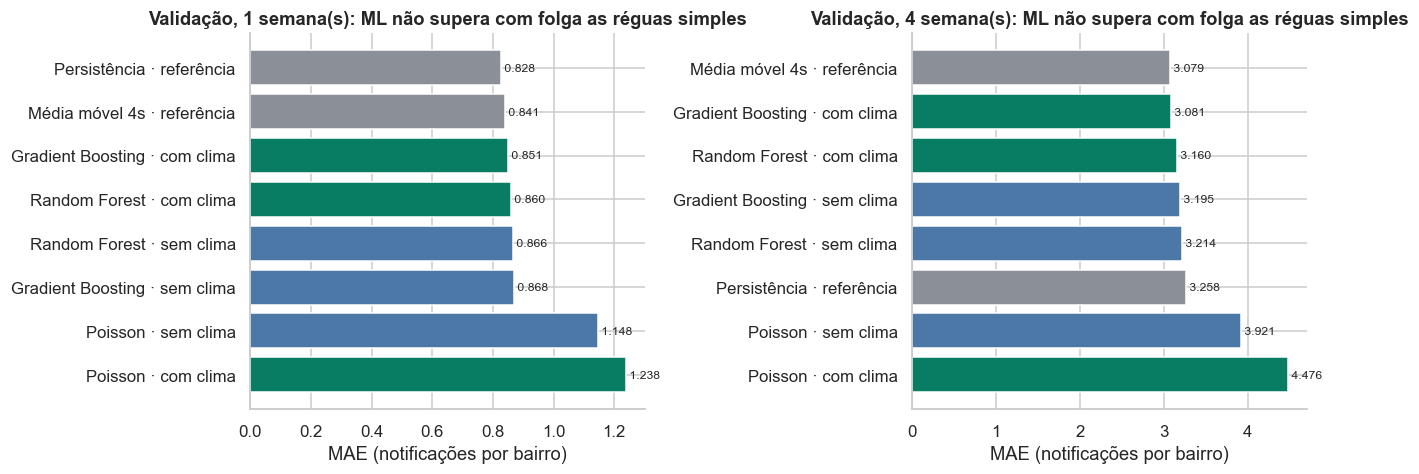

In [6]:
import matplotlib.pyplot as plt

colunas_resumo = ['horizonte_semanas', 'modelo', 'cenario', 'MAE', 'RMSE', 'MAE_picos', 'MAE_municipal']
display(metricas_validacao[colunas_resumo].round(3))

cores = {'baseline': '#8a8f98', 'sem clima': '#4c78a8', 'com clima': '#087d64'}

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.2), layout='constrained')
for eixo, semanas in zip(eixos, (1, 4)):
    parte = metricas_validacao.loc[metricas_validacao['horizonte_semanas'].eq(semanas)].copy()
    parte['rotulo'] = parte['modelo'].str.replace('Média das quatro semanas anteriores', 'Média móvel 4s') + ' · ' + parte['cenario'].replace('baseline', 'referência')
    parte = parte.sort_values('MAE', ascending=False)
    eixo.barh(parte['rotulo'], parte['MAE'], color=parte['cenario'].map(cores))
    for y, valor in enumerate(parte['MAE']):
        eixo.text(valor, y, f' {valor:.3f}', va='center', fontsize=8)
    eixo.set(title=f'Validação, {semanas} semana(s): ML não supera com folga as réguas simples', xlabel='MAE (notificações por bairro)')

plt.show()

> **❓ Pergunta:** Algum modelo de ML supera as réguas simples na validação?
>
> **💡 Insight:** O Poisson foi o pior candidato nos dois horizontes, e o clima até o piorou: um modelo linear não capta bem as relações defasadas e não lineares. Random Forest e Gradient Boosting melhoraram com clima. Em quatro semanas, o Gradient Boosting com clima (3,081) empatou com a média móvel (3,079); em uma semana, nenhum modelo superou a persistência. A validação, portanto, não deu vitória clara ao ML, o que motivou levar as referências também ao teste.

## Avaliação

O limite de pico é o percentil 90 dos alvos positivos no treino de cada horizonte. A coluna MAE_municipal calcula o erro absoluto da soma das previsões dos 94 bairros em cada janela. As tabelas a seguir mostram a variação dos erros ao acrescentar clima. Valores negativos na diferença indicam melhora. Os trimestres usam a primeira semana-alvo de cada janela. O teste fica reservado para a avaliação da configuração escolhida.

In [7]:
from IPython.display import display

pareadas = previsoes_validacao.loc[previsoes_validacao['cenario'].ne('baseline')].copy()
pareadas['erro_absoluto'] = (pareadas['observado'] - pareadas['previsto']).abs()
pareadas['trimestre'] = pareadas['DATA_ALVO'].dt.to_period('Q')
chave = ['horizonte_semanas', 'modelo']

por_periodo = pareadas.groupby(chave + ['trimestre', 'cenario'])['erro_absoluto'].mean().unstack()
por_periodo['diferenca_com_menos_sem'] = por_periodo['com clima'] - por_periodo['sem clima']
display(por_periodo.round(3))

por_bairro = pareadas.groupby(chave + ['BAIRRO', 'cenario'])['erro_absoluto'].mean().unstack()
por_bairro['melhorou'] = por_bairro['com clima'] < por_bairro['sem clima']
display(por_bairro.groupby(level=chave)['melhorou'].sum().rename('bairros com MAE menor').to_frame())

cenario                                        com clima  sem clima  diferenca_com_menos_sem
horizonte_semanas modelo            trimestre                                               
1                 Gradient Boosting 2020Q1         0.760      0.772                   -0.012
                                    2020Q2         0.689      0.690                   -0.001
                                    2020Q3         1.059      1.080                   -0.021
                                    2020Q4         0.751      0.808                   -0.057
                  Poisson           2020Q1         0.747      0.734                    0.013
                                    2020Q2         1.331      1.113                    0.218
                                    2020Q3         1.321      1.310                    0.011
                                    2020Q4         0.914      0.942                   -0.028
                  Random Forest     2020Q1         0.804      0.793                    0.011
                                    2020Q2         0.699      0.682                    0.016
                                    2020Q3         1.057      1.071                   -0.014
                                    2020Q4         0.771      0.830                   -0.060
4                 Gradient Boosting 2020Q1         3.417      3.385                    0.033
                                    2020Q2         3.182      3.360                   -0.178
                                    2020Q3         2.998      3.055                   -0.057
                                    2020Q4         2.187      2.511                   -0.325
                  Poisson           2020Q1         2.742      2.554                    0.188
                                    2020Q2         5.583      4.342                    1.241
                                    2020Q3         3.772      3.784                   -0.012
                                    2020Q4         2.708      2.954                   -0.246
                  Random Forest     2020Q1         3.459      3.476                   -0.016
                                    2020Q2         3.147      3.254                   -0.107
                                    2020Q3         3.203      3.181                    0.021
                                    2020Q4         2.169      2.586                   -0.418

bairros com MAE menor
horizonte_semanas modelo                                  
1                 Gradient Boosting                     54
                  Poisson                                6
                  Random Forest                         40
4                 Gradient Boosting                     69
                  Poisson                               10
                  Random Forest                         51

> **❓ Pergunta:** Qual modelo aproveita melhor o clima?
>
> **💡 Insight:** Em quatro semanas, o Gradient Boosting com clima errou menos que sem clima em três dos quatro trimestres da validação, e o clima reduziu o erro em 69 dos 94 bairros. É o candidato que mais aproveita o clima. Para o Poisson, o clima atrapalhou no segundo trimestre (+1,24).

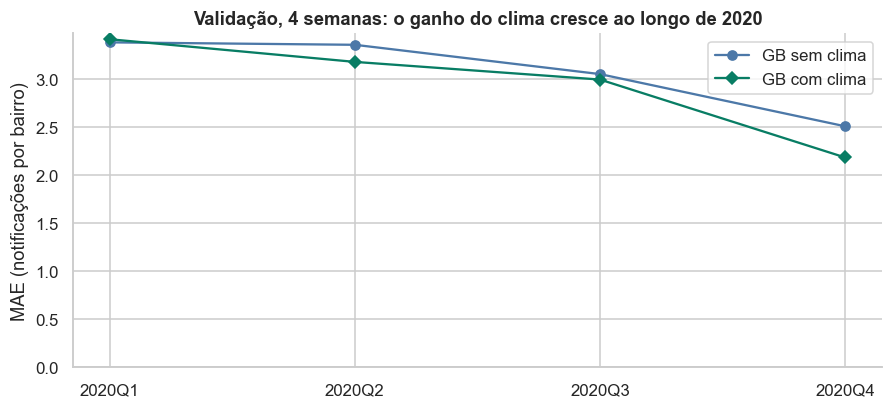

In [8]:
gb4 = por_periodo.loc[(4, 'Gradient Boosting')]

fig, ax = plt.subplots(figsize=(8, 3.6), layout='constrained')
rotulos = [str(p) for p in gb4.index]
ax.plot(rotulos, gb4['sem clima'], marker='o', color=cores['sem clima'], label='GB sem clima')
ax.plot(rotulos, gb4['com clima'], marker='D', color=cores['com clima'], label='GB com clima')
ax.set(title='Validação, 4 semanas: o ganho do clima cresce ao longo de 2020', ylabel='MAE (notificações por bairro)', ylim=(0, None))
ax.legend()
plt.show()

> **❓ Pergunta:** O efeito do clima é igual ao longo do tempo?
>
> **💡 Insight:** O ganho do clima aumenta ao longo de 2020 e é maior no quarto trimestre (erro de 2,51 para 2,19). O efeito não é constante: depende do momento epidemiológico.

### Verificação de robustez: hiperparâmetros do Gradient Boosting

Existe um equilíbrio entre `learning_rate` e número de árvores: taxa alta com muitas árvores aprende rápido, mas tende a sobreajustar; taxa baixa corrige aos poucos e costuma generalizar melhor. A configuração do teste foi fixada antes, sem busca. Para saber se a conclusão depende dessa escolha, variamos **só na validação** de quatro semanas a taxa de aprendizado (0,05; 0,1; 0,2), o número de árvores (100; 300) e o tamanho das árvores (15; 31 folhas), nas versões com e sem clima. São 24 ajustes, feitos por `python -B -m AV2.src.sensibilidade_hiperparametros`. O modelo do teste não foi trocado.

cenario                                com clima  sem clima  ganho_do_clima
learning_rate max_iter max_leaf_nodes                                      
0.05          100      15                  2.985      3.095           0.109
                       31                  3.049      3.196           0.147
              300      15                  3.147      3.281           0.133
                       31                  3.262      3.430           0.168
0.10          100      15                  3.081      3.195           0.114
                       31                  3.192      3.344           0.152
              300      15                  3.276      3.403           0.127
                       31                  3.420      3.627           0.206
0.20          100      15                  3.331      3.315          -0.015
                       31                  3.420      3.536           0.116
              300      15                  3.576      3.572          -0.004
                       31                  3.551      3.831           0.280

Configurações em que o clima reduziu o MAE: 10 de 12


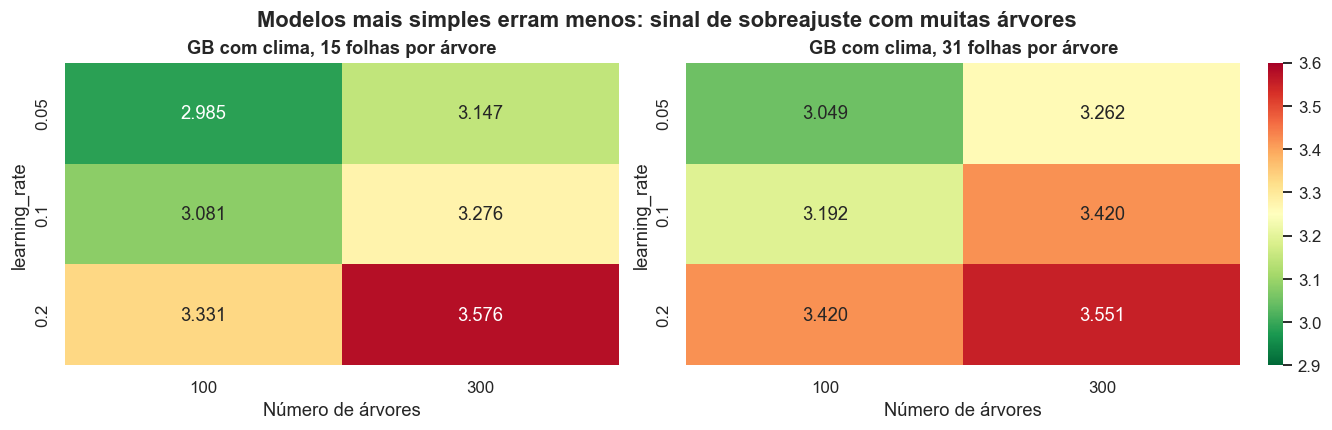

In [9]:
from zipfile import ZipFile

with ZipFile(raiz / 'AV2' / 'artefatos' / 'hiperparametros.zip') as registro:
    with registro.open('grade.csv') as arquivo:
        grade = pd.read_csv(arquivo)

# Ganho do clima em cada configuração (positivo = clima reduziu o erro)
pares = grade.pivot_table(index=['learning_rate', 'max_iter', 'max_leaf_nodes'], columns='cenario', values='MAE')
pares['ganho_do_clima'] = pares['sem clima'] - pares['com clima']
display(pares.round(3))

print('Configurações em que o clima reduziu o MAE:', int((pares['ganho_do_clima'] > 0).sum()), 'de', len(pares))

fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8), layout='constrained')
for eixo, folhas in zip(eixos, (15, 31)):
    mapa = (grade.loc[grade['cenario'].eq('com clima') & grade['max_leaf_nodes'].eq(folhas)]
            .pivot(index='learning_rate', columns='max_iter', values='MAE'))
    sns.heatmap(mapa, annot=True, fmt='.3f', cmap='RdYlGn_r', vmin=2.9, vmax=3.6, ax=eixo, cbar=folhas == 31)
    eixo.set(title=f'GB com clima, {folhas} folhas por árvore', xlabel='Número de árvores', ylabel='learning_rate')

fig.suptitle('Modelos mais simples erram menos: sinal de sobreajuste com muitas árvores', fontweight='bold')
plt.show()

> **❓ Pergunta:** A conclusão sobre o clima depende da configuração escolhida?
>
> **💡 Insight:** Não. O clima reduziu o erro em 10 das 12 configurações, então o ganho climático não é um acaso da configuração congelada. A grade também mostra um padrão claro: **mais árvores, árvores maiores e taxas maiores pioram a validação**, um sinal de sobreajuste. A configuração mais simples (`learning_rate=0,05`, 100 árvores, 15 folhas) teve MAE de 2,985 com clima, melhor que a configuração congelada (3,081) e que a média móvel (3,079). Ela **não** foi levada ao teste, porque o protocolo fixou a configuração antes e o teste só pode ser usado uma vez. Fica como a principal melhoria para uma próxima rodada, junto com uma busca mais ampla por regularização.

## Modelo final: escolha e justificativa

> ### ✅ Modelo final: **Gradient Boosting com clima** (chuva, umidade e temperatura), horizonte de **quatro semanas**
>
> **Por quê, em quatro motivos:**
> 1. **Melhor candidato de ML na validação**, nos dois horizontes, com e sem clima. Poisson e Random Forest erraram mais.
> 2. **A versão com clima errou menos que a sem clima já na validação** (MAE 3,081 contra 3,195 em quatro semanas, 69 de 94 bairros melhores). A escolha do cenário foi feita antes do teste.
> 3. **Adequado ao problema:** a perda Poisson é feita para contagens, e as árvores em sequência captam relações não lineares e defasadas entre clima e notificações.
> 4. **Confirmado no teste reservado:** menor erro em todos os aspectos medidos (MAE 2,882 contra 2,978 sem clima e 3,835 da média móvel; R² 0,70), como resume o radar mais adiante.
>
> O horizonte de quatro semanas é o principal porque é onde o clima ajuda de forma clara e porque dá tempo para a vigilância agir. Para a semana seguinte, o ganho do clima foi pequeno (0,8%).

**Detalhes da escolha do algoritmo (HistGradientBoostingRegressor, perda Poisson).** Na validação, ele teve o menor MAE entre os candidatos de ML nos dois horizontes e com e sem clima. Também foi o que mais se beneficiou do clima (54 bairros com erro menor em uma semana e 69 em quatro semanas, contra 40/51 do Random Forest e 6/10 do Poisson). A perda Poisson combina com um alvo de contagem não negativa, o modelo lida com interações e relações não lineares sem exigir escala, e o ajuste leva poucos segundos. Na validação, porém, nenhum modelo de ML superou com folga as referências simples: em uma semana a persistência teve o menor MAE (0,828) e em quatro semanas a média móvel (3,079) empatou com o Gradient Boosting com clima (3,081). Por isso as duas referências também foram ao teste, e a conclusão depende do teste reservado, não da validação.

**Referências levadas ao teste:** persistência para uma semana e média móvel para quatro semanas, pois foram as réguas simples com menor MAE de validação em cada horizonte.

**Parâmetros fixos, sem busca.** A validação cobre poucos meses de 2020. Fazer uma busca extensa nela aumentaria o risco de ajustar ao acaso dessa amostra. Os parâmetros foram fixados antes da comparação e mantidos iguais nas duas versões, de modo que a única diferença entre elas é o bloco climático.

**Temperatura mantida.** Na validação, retirar a temperatura reduziu o MAE (seção de sensibilidades). Ela continuou no modelo porque a pergunta científica testa o bloco climático definido no protocolo (chuva, temperatura e umidade), e a configuração foi congelada antes do teste. Removê-la depois de ver esse resultado seria uma escolha guiada pela própria amostra de avaliação. Mais adiante, na seção "A temperatura no Recife", explicamos por que ela ajuda pouco e mostramos, como análise posterior, que retirá-la piorou o teste.

Após a aprovação, cada versão foi ajustada na união de treino e validação, com os mesmos parâmetros. O teste foi executado em um comando separado (`python -B -m AV2.src.avaliar_teste_final`), que se recusa a rodar de novo quando o resultado já existe. As células seguintes leem o resultado registrado.

In [10]:
from zipfile import ZipFile

# Lê o teste oficial já registrado (executado uma única vez por avaliar_teste_final.py)
with ZipFile(raiz / 'AV2' / 'artefatos' / 'teste_final.zip') as registro:
    with registro.open('metricas.csv') as tabela_teste:
        metricas_teste = pd.read_csv(tabela_teste)
    with registro.open('previsoes.csv') as tabela_previsoes:
        previsoes_teste = pd.read_csv(tabela_previsoes, parse_dates=['DATA_ALVO', 'DATA_FIM_ALVO'])

display(metricas_teste.round(3))

mae_teste = metricas_teste.pivot(index='horizonte_semanas', columns='cenario', values='MAE')
display(pd.DataFrame({
    'redução de MAE contra a referência (%)': 100 * (1 - mae_teste['com clima'] / mae_teste['baseline']),
    'redução de MAE contra a versão sem clima (%)': 100 * (1 - mae_teste['com clima'] / mae_teste['sem clima']),
}).round(2))

,horizonte_semanas,modelo,cenario,linhas,MAE,RMSE,MAE_positivos,MAE_picos,n_picos,MAE_municipal
0,1,Persistência,baseline,3102,1.132,3.188,2.747,7.143,210,32.364
1,1,Gradient Boosting,sem clima,3102,1.024,2.699,2.305,6.931,210,26.049
2,1,Gradient Boosting,com clima,3102,1.016,2.705,2.248,6.579,210,31.320
3,4,Média das quatro semanas anteriores,baseline,2820,3.835,10.833,5.911,18.166,319,210.567
4,4,Gradient Boosting,sem clima,2820,2.978,7.641,4.346,15.200,319,141.360
5,4,Gradient Boosting,com clima,2820,2.882,7.434,4.181,14.208,319,94.260


,redução de MAE contra a referência (%),redução de MAE contra a versão sem clima (%)
horizonte_semanas,,
1,10.22,0.79
4,24.85,3.22


In [11]:
from sklearn.metrics import r2_score

# R² por horizonte e cenário (fração da variação explicada)
r2_teste = (previsoes_teste.groupby(['horizonte_semanas', 'cenario'])
            .apply(lambda g: r2_score(g['observado'], g['previsto']), include_groups=False)
            .unstack().round(3))

r2_teste.columns.name = 'R² no teste'
r2_teste

R² no teste,baseline,com clima,sem clima
horizonte_semanas,,,
1,0.349,0.531,0.533
4,0.360,0.698,0.681


> **❓ Pergunta:** Quanto da variação das notificações o modelo explica?
>
> **💡 Insight:** O R² complementa o MAE: ele mede a fração da variação entre bairros e semanas que o modelo explica (1 = perfeito, 0 = igual a prever sempre a média). O Gradient Boosting explica cerca de 53% da variação em uma semana e 70% em quatro semanas, contra cerca de 35% da referência simples. Com clima, o R² sobe em quatro semanas (de 0,681 para 0,698) e fica praticamente igual em uma semana, o mesmo padrão do MAE. O R² é alto também porque bairros grandes têm sempre mais registros que bairros pequenos; por isso o MAE, em notificações, continua sendo a métrica principal.

### Perfil dos modelos: visão geral em radar

Cada métrica olha para um aspecto diferente do erro: o erro médio (MAE), os erros grandes (RMSE), os surtos (erro nos picos), o total da cidade, a variação explicada (R²) e a utilidade para priorizar bairros (quantos dos dez bairros com mais notificações no mês o modelo aponta). O radar junta tudo em uma figura. Para comparar escalas diferentes, cada eixo mostra uma **nota relativa de 0 a 1**, em que **1 é o melhor modelo naquele aspecto**: nas métricas de erro, nota = menor erro ÷ erro do modelo; no R² e na priorização, nota = valor do modelo ÷ maior valor. Quanto **maior a área**, melhor o modelo. Horizonte de quatro semanas, teste reservado; a priorização vem da avaliação mensal.

valor                                                 nota                                             
             MAE    RMSE MAE_picos MAE_municipal     R2  top10    MAE   RMSE MAE_picos MAE_municipal     R2  top10
cenario                                                                                                           
baseline   3.835  10.833    18.166       210.567  0.360  4.714  0.751  0.686     0.782         0.448  0.516  0.868
sem clima  2.978   7.641    15.200       141.360  0.681  5.000  0.968  0.973     0.935         0.667  0.976  0.921
com clima  2.882   7.434    14.208        94.260  0.698  5.429  1.000  1.000     1.000         1.000  1.000  1.000

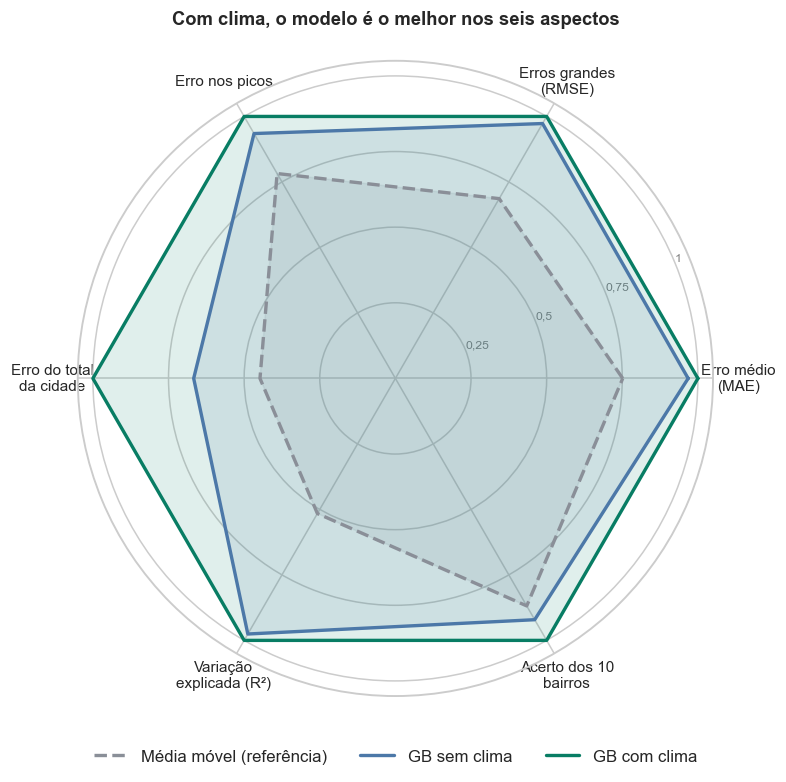

In [12]:
import textwrap

import numpy as np

# 1. Junta as seis métricas do teste de 4 semanas (a priorização vem da avaliação mensal)
with ZipFile(raiz / 'AV2' / 'artefatos' / 'sensibilidades.zip') as registro:
    with registro.open('priorizacao_mensal.csv') as arquivo:
        top10 = pd.read_csv(arquivo).groupby('cenario')['bairros_em_comum_top10'].mean()

perfil = metricas_teste.loc[metricas_teste['horizonte_semanas'].eq(4)].set_index('cenario')
perfil['R2'] = r2_teste.loc[4]
perfil['top10'] = top10.rename({'média móvel': 'baseline'})

# 2. Converte cada métrica em nota de 0 a 1 (1 = melhor modelo naquele aspecto)
erros = {'MAE': 'Erro médio (MAE)', 'RMSE': 'Erros grandes (RMSE)', 'MAE_picos': 'Erro nos picos',
         'MAE_municipal': 'Erro do total da cidade'}

acertos = {'R2': 'Variação explicada (R²)', 'top10': 'Acerto dos 10 bairros'}
notas = pd.concat([perfil[list(erros)].min() / perfil[list(erros)],      # menor erro / erro do modelo
                   perfil[list(acertos)] / perfil[list(acertos)].max()], # valor do modelo / maior valor
                  axis=1)

display(pd.concat({'valor': perfil[notas.columns], 'nota': notas}, axis=1).round(3))

# 3. Desenha o radar (o polígono é fechado repetindo o primeiro ponto)
rotulos = [textwrap.fill(r, 14) for r in {**erros, **acertos}.values()]
angulos = np.linspace(0, 2 * np.pi, len(rotulos), endpoint=False).tolist()
angulos += angulos[:1]

fig, ax = plt.subplots(figsize=(7.5, 7.5), subplot_kw={'polar': True})
for cenario, nome, estilo in [('baseline', 'Média móvel (referência)', '--'),
                              ('sem clima', 'GB sem clima', '-'),
                              ('com clima', 'GB com clima', '-')]:
    valores = notas.loc[cenario].tolist()
    valores += valores[:1]
    ax.plot(angulos, valores, color=cores[cenario], linewidth=2.2, linestyle=estilo, label=nome)
    ax.fill(angulos, valores, color=cores[cenario], alpha=0.12)

ax.set_xticks(angulos[:-1], rotulos, fontsize=10)
ax.set_ylim(0, 1.05)
ax.set_yticks([0.25, 0.5, 0.75, 1.0], ['0,25', '0,5', '0,75', '1'], fontsize=8, color='gray')
ax.set_title('Com clima, o modelo é o melhor nos seis aspectos', pad=24, fontweight='bold')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=3, frameon=False)
plt.show()

> **❓ Pergunta:** Olhando todos os aspectos juntos, qual modelo é melhor?
>
> **💡 Insight:** A área verde (com clima) envolve as outras: ele tem o menor erro médio, o menor erro nos picos, o menor erro do total da cidade, o maior R² e aponta mais bairros prioritários. A maior vantagem do clima está no **total da cidade** (erro de 94 contra 141 sem clima), o que reforça o fio da história: o clima ajuda a antecipar a tendência. Nos erros grandes (RMSE) e no R² a diferença entre com e sem clima é pequena. A média móvel tem a menor área em todos os eixos, o que mostra que o ML vale a pena aqui.

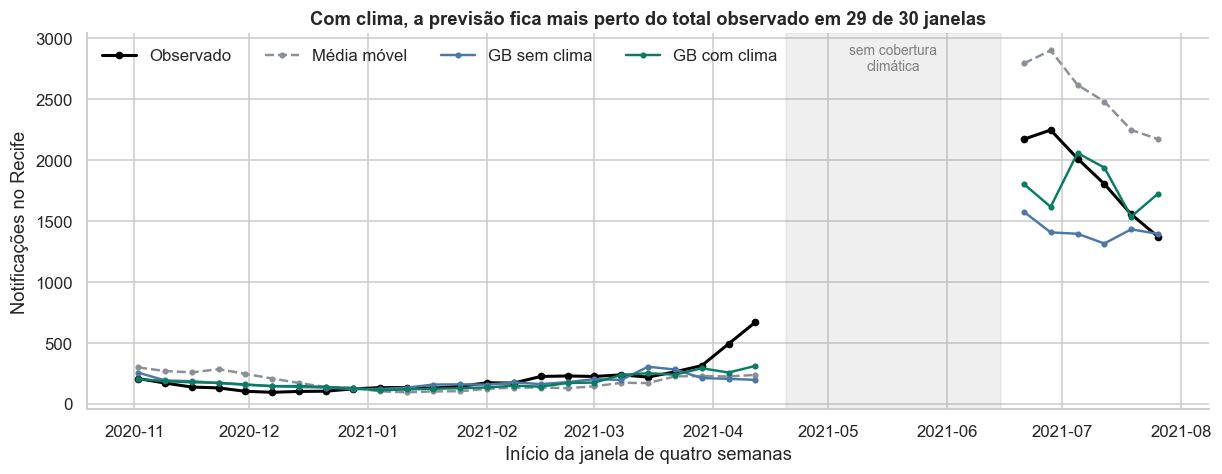

Bairros com MAE menor ao acrescentar clima: 48


,BAIRRO,DATA_ALVO,DATA_FIM_ALVO,observado,previsto,erro_absoluto
16320,IBURA,2021-06-21,2021-07-12,141.0,48.75,92.25
17732,VASCO DA GAMA,2021-07-05,2021-07-26,57.0,140.11,83.11
17733,VASCO DA GAMA,2021-07-12,2021-08-02,45.0,125.60,80.60
17734,VASCO DA GAMA,2021-07-19,2021-08-09,35.0,115.39,80.39
15331,BOA VIAGEM,2021-06-28,2021-07-19,103.0,33.70,69.30


In [13]:
import matplotlib.pyplot as plt

mensal_movel = previsoes_teste.loc[previsoes_teste['horizonte_semanas'].eq(4)].copy()
municipio = mensal_movel.groupby(['DATA_ALVO', 'cenario'])[['observado', 'previsto']].sum().unstack()

# Total do Recife por janela; as lacunas são janelas sem cobertura climática completa
# Reindexa semana a semana para a linha se interromper nas janelas sem previsão
municipio = municipio.reindex(pd.date_range(municipio.index.min(), municipio.index.max(), freq='7D'))

fig, ax = plt.subplots(figsize=(11, 4.2), layout='constrained')
ax.plot(municipio.index, municipio['observado']['baseline'], color='black', marker='o', markersize=4, linewidth=2, label='Observado')
for nome, tipo, estilo in [('Média móvel', 'baseline', '--'), ('GB sem clima', 'sem clima', '-'), ('GB com clima', 'com clima', '-')]:
    ax.plot(municipio.index, municipio['previsto'][tipo], color=cores[tipo], linestyle=estilo, marker='.', linewidth=1.6, label=nome)

ax.axvspan(pd.Timestamp('2021-04-20'), pd.Timestamp('2021-06-15'), color='gray', alpha=0.12)
ax.text(pd.Timestamp('2021-05-18'), ax.get_ylim()[1] * 0.9, 'sem cobertura\nclimática', ha='center', fontsize=9, color='gray')
ax.set(xlabel='Início da janela de quatro semanas', ylabel='Notificações no Recife',
       title='Com clima, a previsão fica mais perto do total observado em 29 de 30 janelas')

ax.legend(frameon=False, ncol=4, loc='upper left')
plt.show()

mensal_movel['erro_absoluto'] = (mensal_movel['previsto'] - mensal_movel['observado']).abs()
mae_bairro = mensal_movel.groupby(['BAIRRO', 'cenario'])['erro_absoluto'].mean().unstack()
print('Bairros com MAE menor ao acrescentar clima:', int((mae_bairro['com clima'] < mae_bairro['sem clima']).sum()))
colunas_erro = ['BAIRRO', 'DATA_ALVO', 'DATA_FIM_ALVO', 'observado', 'previsto', 'erro_absoluto']
mensal_movel.loc[mensal_movel['cenario'].eq('com clima')].nlargest(5, 'erro_absoluto')[colunas_erro].round(2)

> **❓ Pergunta:** O modelo acompanha a curva da cidade no teste?
>
> **💡 Insight:** No total da cidade, as previsões acompanham o nível das janelas, mas oscilam em torno do pico de meados de 2021 (máximo observado na janela iniciada em 28/06/2021). A versão com clima ficou mais perto do total observado do que a média móvel em 29 das 30 janelas.

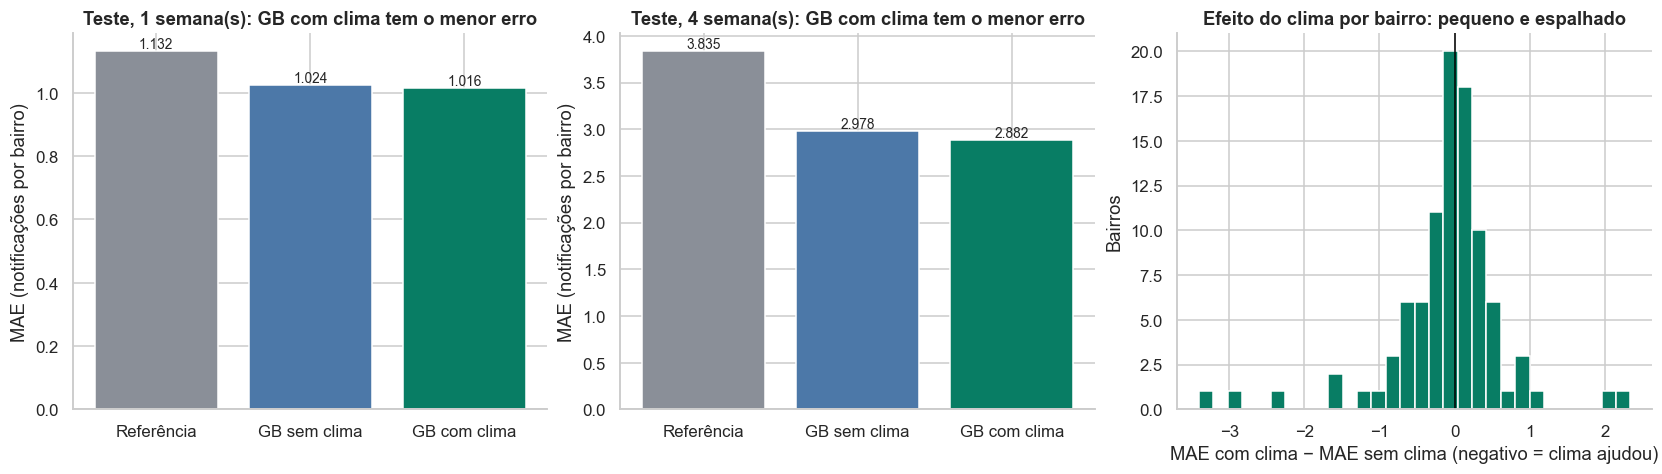

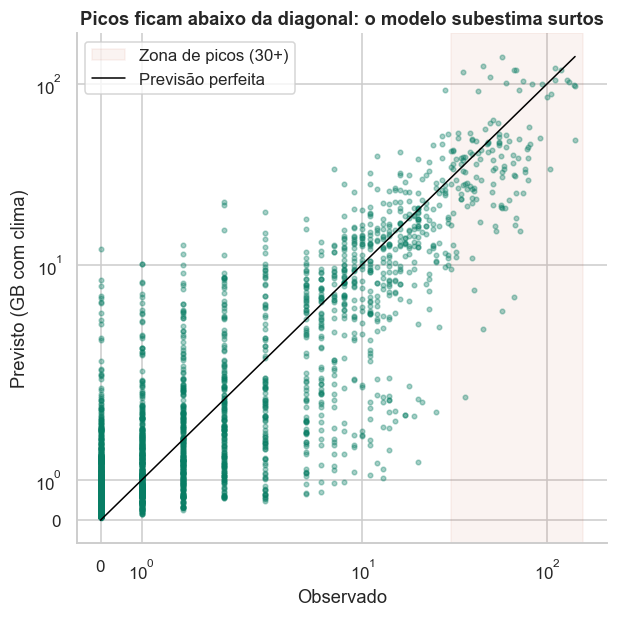

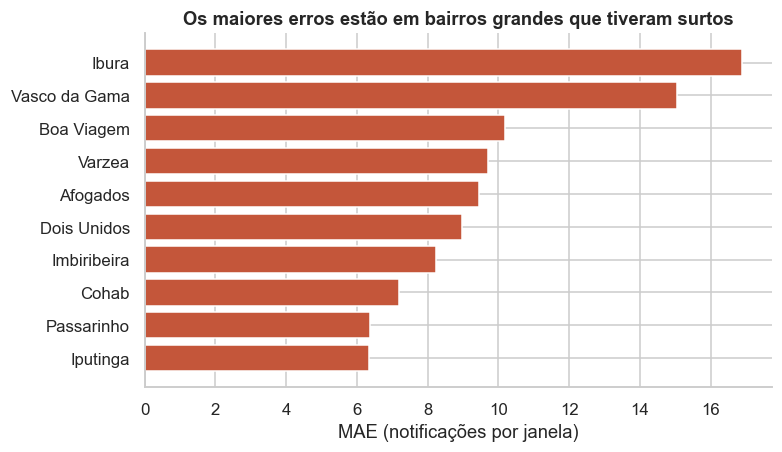

In [14]:
metricas_teste_rot = metricas_teste.assign(rotulo=metricas_teste['modelo'].str.replace('Média das quatro semanas anteriores', 'Média móvel 4s') + ' · ' + metricas_teste['cenario'])

fig, eixos = plt.subplots(1, 3, figsize=(15, 4.2), layout='constrained')
for eixo, semanas in zip(eixos[:2], (1, 4)):
    parte = metricas_teste_rot.loc[metricas_teste_rot['horizonte_semanas'].eq(semanas)]
    eixo.bar(parte['cenario'], parte['MAE'], color=parte['cenario'].map(cores))
    for x, valor in enumerate(parte['MAE']):
        eixo.text(x, valor, f'{valor:.3f}', ha='center', va='bottom', fontsize=9)
    eixo.set(title=f'Teste, {semanas} semana(s): GB com clima tem o menor erro', ylabel='MAE (notificações por bairro)')
    eixo.set_xticks(range(len(parte)), ['Referência', 'GB sem clima', 'GB com clima'])

diferenca = (mae_bairro['com clima'] - mae_bairro['sem clima']).sort_values()
eixos[2].hist(diferenca, bins=30, color=cores['com clima'])
eixos[2].axvline(0, color='black', linewidth=1)
eixos[2].set(title='Efeito do clima por bairro: pequeno e espalhado', xlabel='MAE com clima − MAE sem clima (negativo = clima ajudou)', ylabel='Bairros')
plt.show()

com_clima = mensal_movel.loc[mensal_movel['cenario'].eq('com clima')]

fig, ax = plt.subplots(figsize=(5.5, 5.5), layout='constrained')

# Escala symlog abre a região perto de zero, onde está a maioria dos bairros
ax.axvspan(30, limite_tmp := float(com_clima[['observado', 'previsto']].max().max()) * 1.1, color='#c4563a', alpha=0.07, label='Zona de picos (30+)')
ax.scatter(com_clima['observado'], com_clima['previsto'], s=9, alpha=0.35, color=cores['com clima'])
ax.set_xscale('symlog', linthresh=5)
ax.set_yscale('symlog', linthresh=5)
limite = float(com_clima[['observado', 'previsto']].max().max())
ax.plot([0, limite], [0, limite], color='black', linewidth=1, label='Previsão perfeita')
ax.set(title='Picos ficam abaixo da diagonal: o modelo subestima surtos', xlabel='Observado', ylabel='Previsto (GB com clima)')
ax.legend()
plt.show()

piores = mae_bairro['com clima'].nlargest(10).sort_values()

fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
ax.barh(piores.index.str.title().str.replace(' Da ', ' da ').str.replace(' Do ', ' do '), piores, color='#c4563a')
ax.set(title='Os maiores erros estão em bairros grandes que tiveram surtos', xlabel='MAE (notificações por janela)')
plt.show()

> **❓ Pergunta:** O resultado se confirma em dados nunca vistos, e onde o modelo erra?
>
> **💡 Insight:** No teste reservado, o Gradient Boosting superou a referência simples nos dois horizontes, e o clima reduziu o erro um pouco mais (0,8% em uma semana e 3,2% em quatro). O histograma mostra que o efeito por bairro é pequeno e espalhado em torno de zero: o clima ajudou em 48 bairros e piorou em 46. No gráfico observado × previsto, os pontos acima de cerca de 30 notificações ficam abaixo da diagonal: em 73% dessas janelas o modelo previu menos que o observado. Os maiores erros se concentram em bairros populosos com surtos, como Ibura, Vasco da Gama e Boa Viagem. Esses picos não são erros de dado: são surtos reais e raros, justamente o evento mais difícil e mais importante de antecipar.

### O ganho do clima é confiável ou pode ser sorte?

O ganho do clima no teste é pequeno (3,2% em quatro semanas). Antes de tirar conclusões, precisamos saber se ele se repetiria em outro período parecido ou se apareceu por acaso. Para isso usamos um **bootstrap**: sorteamos com reposição as semanas do teste, recalculamos o erro dos modelos e repetimos isso 5.000 vezes. É como jogar a mesma partida muitas vezes para ver se um time ganha de verdade ou só ganhou aquela.

Como semanas vizinhas se parecem (e as janelas de quatro semanas se sobrepõem), sorteamos **blocos de quatro semanas seguidas**, e não semanas soltas (*bootstrap* em blocos circulares). As previsões são as mesmas já registradas no teste: nada é treinado de novo e o teste não é reutilizado para escolher nada.

Comparamos três ganhos: **com clima × sem clima** por bairro, o mesmo no **total da cidade** e **com clima × média móvel** (o ganho de usar ML). Para cada um, mostramos o intervalo onde caem 95% dos sorteios e em quantos sorteios o ganho foi positivo.

,horizonte_semanas,comparação,ganho_mediano_%,IC95_inferior_%,IC95_superior_%,sorteios_com_ganho_%
0,1,Clima × sem clima (bairro),0.8,-0.7,2.3,84.4
1,1,Clima × sem clima (cidade),-19.0,-41.8,10.2,13.4
2,1,ML com clima × média móvel,9.9,-1.5,14.9,95.9
3,4,Clima × sem clima (bairro),3.4,-3.0,7.6,87.0
4,4,Clima × sem clima (cidade),31.8,-26.4,49.3,91.1
5,4,ML com clima × média móvel,24.6,7.3,30.7,99.5


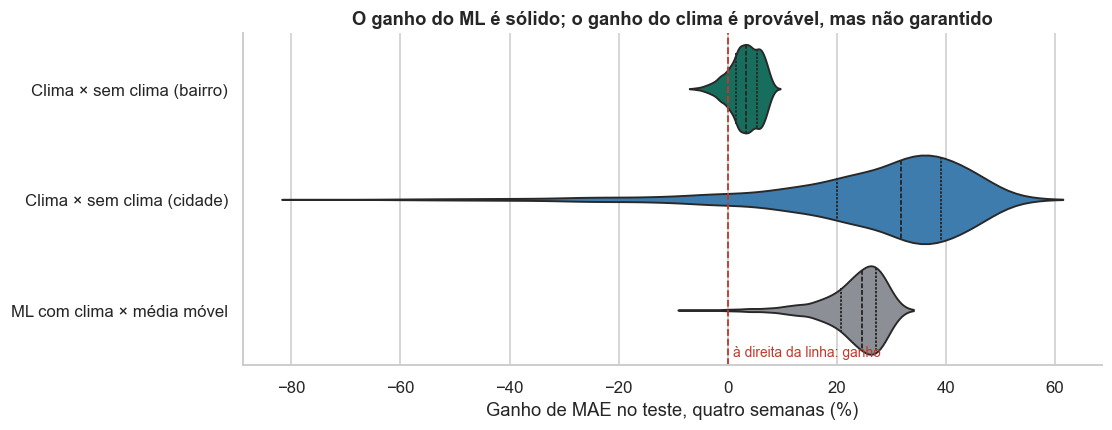

In [15]:
from AV2.src.analises_clima import bootstrap_ganhos

# Bootstrap em blocos de 4 semanas sobre as previsões do teste já registradas (código em src/analises_clima.py)
resumos, sorteados = zip(*(bootstrap_ganhos(previsoes_teste, semanas) for semanas in (1, 4)))
display(pd.concat(resumos, ignore_index=True).round(1))

# Distribuição dos ganhos em quatro semanas
dist = pd.DataFrame(sorteados[1]).melt(var_name='comparação', value_name='ganho (%)')
fig, ax = plt.subplots(figsize=(10, 3.8), layout='constrained')
sns.violinplot(data=dist, x='ganho (%)', y='comparação', hue='comparação', inner='quartile', cut=0,
               palette=['#087d64', '#2a7fbf', '#8a8f98'], legend=False, ax=ax)
ax.axvline(0, color='#c0392b', linestyle='--', linewidth=1.2)
ax.text(1, 2.42, 'à direita da linha: ganho', color='#c0392b', fontsize=9)
ax.set(ylabel='', xlabel='Ganho de MAE no teste, quatro semanas (%)')
ax.set_title('O ganho do ML é sólido; o ganho do clima é provável, mas não garantido', fontweight='bold')
plt.show()

> **❓ Pergunta:** O ganho do clima é real ou pode ter sido sorte do período de teste?
>
> **💡 Insight:** Depende do ganho. **Usar ML vale a pena com segurança:** em quatro semanas, o Gradient Boosting com clima superou a média móvel em 99% dos sorteios (intervalo de cerca de 7% a 31%). **O ganho do clima é provável, mas não garantido:** em quatro semanas, ele aparece em cerca de 87% dos sorteios por bairro e 91% no total da cidade, mas o intervalo de 95% passa pelo zero (cerca de −3% a +8% por bairro). Em uma semana, o ganho por bairro é mínimo, e no total da cidade o clima até piora. Em linguagem simples: o clima tende a ajudar no médio prazo, mas um único ano de teste, curto e no meio da pandemia, não basta para **provar** isso estatisticamente. É um **indício**, não uma prova, e é assim que o resultado deve ser comunicado. Confirmar o efeito exige mais anos de dados com clima.

### O clima avisa antes: o sinal que antecede a alta

O *bootstrap* responde a uma pergunta estreita: **quanto o clima acrescenta à previsão quando o modelo já conhece o histórico recente de notificações**. Esse ganho é pequeno porque, quando a dengue começa a subir, o histórico já carrega boa parte da informação. Mas isso não quer dizer que o clima seja irrelevante. A pergunta da gestão é outra: **o clima muda antes das notificações?** Se mudar, ele funciona como um alarme que toca antes de o problema aparecer nos registros.

Para medir isso, juntamos a cidade inteira por semana (2016 a 2021, período com dados climáticos) e calculamos a correlação de Spearman entre o clima de **L semanas antes** e as notificações da semana, para L de 0 a 16. Para que anos de epidemia muito grande (como 2016) não dominem o resultado, as notificações entram como desvio em relação à média do próprio ano. Ao lado, o calendário típico (mediana de cada mês, que não deixa um ano epidêmico distorcer a figura) mostra em que meses chove mais e em que meses as notificações sobem.

,Chuva,Umidade,Temperatura
semanas antes,,,
0,0.32,0.27,-0.38
2,0.40,0.37,-0.40
4,0.47,0.44,-0.35
6,0.42,0.44,-0.26
8,0.40,0.42,-0.20
12,0.32,0.34,0.02
16,0.18,0.14,0.26


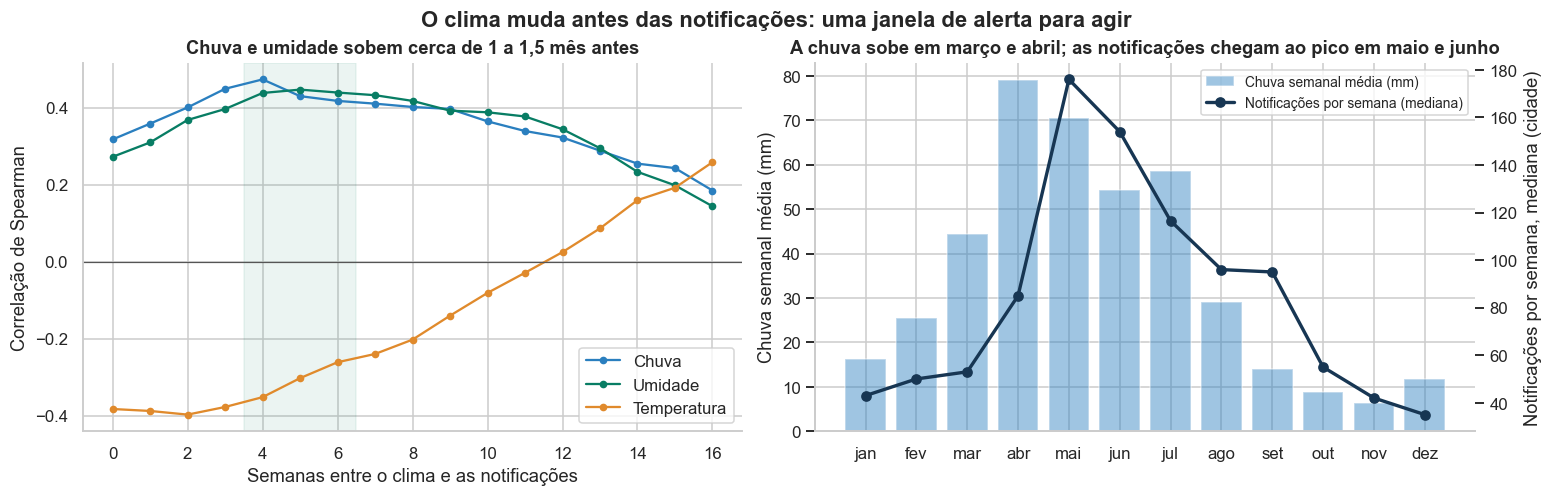

In [16]:
from AV2.src.analises_clima import sinal_climatico

# Correlação clima de L semanas antes x notificações (desvio da média do ano) e calendário típico
correl_defas, calendario = sinal_climatico(painel)
display(correl_defas.loc[[0, 2, 4, 6, 8, 12, 16]].round(2))

cores_sinal = {'Chuva': '#2a7fbf', 'Umidade': '#087d64', 'Temperatura': '#e08a2c'}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.4), layout='constrained')

for nome, cor in cores_sinal.items():
    ax1.plot(correl_defas.index, correl_defas[nome], marker='o', markersize=4, color=cor, label=nome)
ax1.axhline(0, color='#555', linewidth=0.8)
ax1.axvspan(3.5, 6.5, color='#087d64', alpha=0.08)
ax1.set(xlabel='Semanas entre o clima e as notificações', ylabel='Correlação de Spearman',
        title='Chuva e umidade sobem cerca de 1 a 1,5 mês antes')
ax1.legend()

meses_nome = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul', 'ago', 'set', 'out', 'nov', 'dez']
ax2.bar(range(12), calendario['chuva'], color='#2a7fbf', alpha=0.45, label='Chuva semanal média (mm)')
ax2.set(ylabel='Chuva semanal média (mm)', xticks=range(12), xticklabels=meses_nome)
ax2b = ax2.twinx()
ax2b.plot(range(12), calendario['notificacoes'], color='#173653', marker='o', linewidth=2.2, label='Notificações por semana (mediana)')
ax2b.set_ylabel('Notificações por semana, mediana (cidade)')
ax2b.grid(False)
ax2.set_title('A chuva sobe em março e abril; as notificações chegam ao pico em maio e junho')
ax2.legend(handles=ax2.get_legend_handles_labels()[0] + ax2b.get_legend_handles_labels()[0], loc='upper right', fontsize=9)

fig.suptitle('O clima muda antes das notificações: uma janela de alerta para agir', fontweight='bold')
plt.show()

> **❓ Pergunta:** Se o ganho na previsão é pequeno, o clima importa para a gestão?
>
> **💡 Insight:** Importa, e a razão está no **tempo**. Chuva e umidade têm correlação moderada (cerca de 0,45) com as notificações de **4 a 6 semanas depois**, mesmo descontando a diferença entre anos epidêmicos e calmos. No calendário típico, a chuva sobe em março e abril e as notificações chegam ao pico em maio e junho, cerca de um mês depois. A temperatura aparece negativa porque, no Recife, os meses mais quentes são os mais secos. Ou seja: **o clima mostra o risco antes de ele aparecer nos registros**. Quando o modelo já conhece as notificações recentes, o clima acrescenta pouco porque a alta já começou e o histórico já a mostra. Para a Prefeitura, isso dá uma janela de cerca de um mês para limpar criadouros e reforçar visitas **antes** do aumento.
>
> ⚠️ Correlação não prova causa: chuva, umidade e dengue seguem a mesma estação. O mecanismo biológico (água parada vira criadouro do *Aedes aegypti*) é conhecido, e os dados do Recife são compatíveis com ele, mas este notebook mede associação e capacidade de previsão, não efeito causal.

### Quando: a antecipação em um bairro

O total da cidade esconde o que acontece em cada bairro. Acompanhamos o Ibura, o bairro com maior erro no teste, janela a janela.

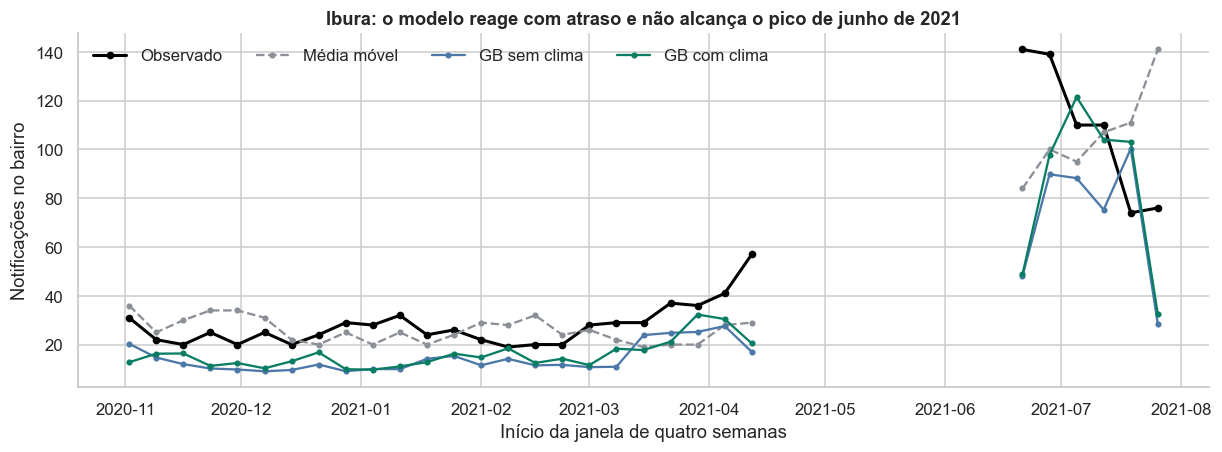

In [17]:
# Série de janelas de 4 semanas de um bairro: observado x previsões
bairro = 'IBURA'
serie = mensal_movel.loc[mensal_movel['BAIRRO'].eq(bairro)].pivot_table(index='DATA_ALVO', columns='cenario', values=['observado', 'previsto'])
serie = serie.reindex(pd.date_range(serie.index.min(), serie.index.max(), freq='7D'))  # quebra a linha nas lacunas

fig, ax = plt.subplots(figsize=(11, 4), layout='constrained')
ax.plot(serie.index, serie['observado']['baseline'], color='black', marker='o', markersize=4, linewidth=2, label='Observado')
for nome, tipo, estilo in [('Média móvel', 'baseline', '--'), ('GB sem clima', 'sem clima', '-'), ('GB com clima', 'com clima', '-')]:
    ax.plot(serie.index, serie['previsto'][tipo], color=cores[tipo], linestyle=estilo, marker='.', label=nome)

ax.set(title='Ibura: o modelo reage com atraso e não alcança o pico de junho de 2021',
       xlabel='Início da janela de quatro semanas', ylabel='Notificações no bairro')

ax.legend(frameon=False, ncol=4, loc='upper left')
plt.show()

> **❓ Pergunta:** O modelo antecipa o aumento em um bairro?
>
> **💡 Insight:** Só em parte. Até março, as previsões com e sem clima ficam um pouco abaixo do observado. Quando o Ibura começa a subir, em abril, elas quase não reagem. No pico de junho de 2021, o modelo previu cerca de 49 notificações contra 141 observadas, e só alcançou o nível do bairro em julho, com atraso. O trecho sem linha corresponde a janelas sem cobertura climática completa. Na prática, o modelo ajuda a acompanhar o nível do bairro, mas **não antecipa o tamanho de um surto local**. Esse é o principal limite para uso operacional.

## Mês de calendário

O alvo mensal soma as notificações pela data civil, do dia 1 ao último dia do mês. A previsão usa apenas entradas disponíveis no fechamento da última semana completa anterior ao dia 1. O Gradient Boosting foi ajustado novamente para esse alvo, mantendo a configuração aprovada e acrescentando a duração do mês e a distância da emissão ao dia 1.

A comparação climática usa os mesmos sete meses completos nos dois cenários. Nos quatro meses sem clima suficiente, a figura mostra só o observado. Como o período está relacionado ao teste semanal já inspecionado, esta é uma avaliação retrospectiva complementar, com apenas sete datas de emissão na comparação. O detalhe semanal do outro experimento permanece disponível com seu próprio horizonte.

,cenario,meses,linhas,MAE,RMSE,MAE_municipal,conjunto
0,média móvel,7,658,3.464,8.144,199.250,validacao
1,sem clima,7,658,3.642,7.624,215.336,validacao
2,com clima,7,658,3.512,7.582,191.745,validacao
3,média móvel,7,658,5.471,14.620,365.582,teste
4,sem clima,7,658,3.933,9.728,220.158,teste
5,com clima,7,658,3.999,9.377,207.187,teste


cenario,com clima,média móvel,sem clima,observado
MES_ALVO,,,,
2020-12-01,170.0,270.0,163.0,111
2021-01-01,122.0,143.0,126.0,139
2021-02-01,146.0,121.0,245.0,171
2021-03-01,198.0,157.0,259.0,258
2021-04-01,332.0,243.0,141.0,496
2021-05-01,NaN,NaN,NaN,1981
2021-06-01,NaN,NaN,NaN,2831
2021-07-01,1748.0,3212.0,1326.0,2244
2021-08-01,2009.0,2405.0,1252.0,1380


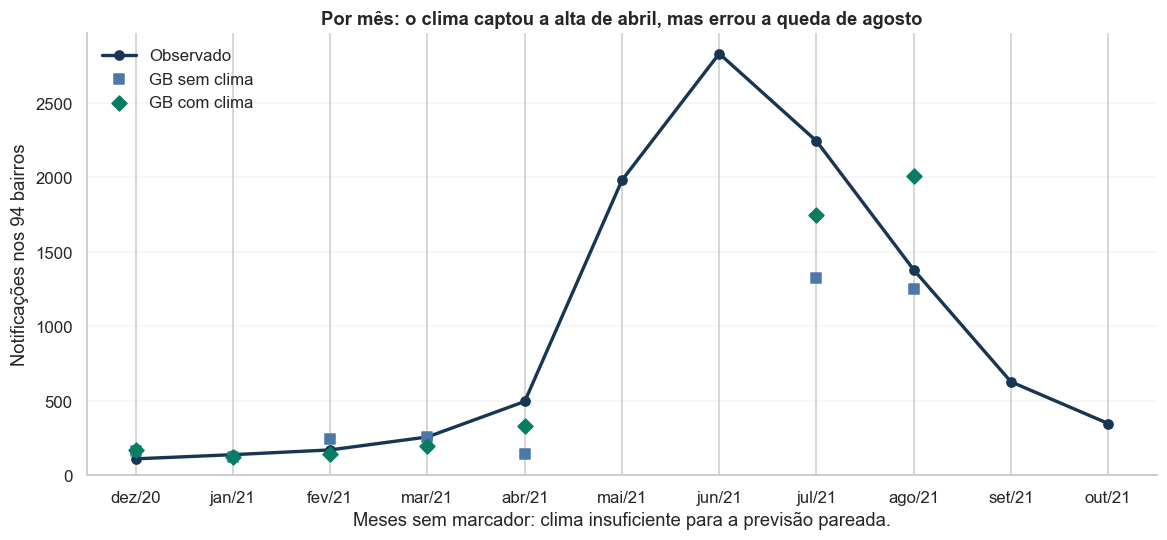

In [18]:
with ZipFile(raiz / 'AV2' / 'artefatos' / 'mes_calendario.zip') as registro:
    with registro.open('metricas.csv') as arquivo:
        metricas_mes = pd.read_csv(arquivo)
    with registro.open('previsoes.csv') as arquivo:
        previsoes_mes = pd.read_csv(arquivo, parse_dates=['MES_ALVO'])
    with registro.open('observados_mes.csv') as arquivo:
        observados_mes = pd.read_csv(arquivo, parse_dates=['MES_ALVO'])
    with registro.open('cobertura_mes.csv') as arquivo:
        cobertura_mes = pd.read_csv(arquivo, parse_dates=['MES_ALVO'])

display(metricas_mes.round(3))

meses_teste = cobertura_mes.loc[cobertura_mes['CONJUNTO_MES'].eq('teste'), 'MES_ALVO']
meses_teste = pd.DatetimeIndex(meses_teste.sort_values())
observado_recife_mes = observados_mes.groupby('MES_ALVO')['observado'].sum().reindex(meses_teste)
previsto_recife_mes = (previsoes_mes.loc[previsoes_mes['conjunto'].eq('teste')]
                       .groupby(['MES_ALVO', 'cenario'])['previsto'].sum().unstack().reindex(meses_teste))

quadro_recife_mes = previsto_recife_mes.assign(observado=observado_recife_mes)
display(quadro_recife_mes.round(0))

fig_mes, ax_mes = plt.subplots(figsize=(10.5, 4.8), layout='constrained')
posicoes = range(len(meses_teste))
meses_pt = ('jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul', 'ago', 'set', 'out', 'nov', 'dez')
ax_mes.plot(posicoes, observado_recife_mes, color='#173653', marker='o', linewidth=2.2, label='Observado')
ax_mes.scatter(posicoes, previsto_recife_mes['sem clima'], color=cores['sem clima'], marker='s', s=40, zorder=3, label='GB sem clima')
ax_mes.scatter(posicoes, previsto_recife_mes['com clima'], color=cores['com clima'], marker='D', s=48, zorder=3, label='GB com clima')
ax_mes.set_xticks(list(posicoes), [f'{meses_pt[d.month - 1]}/{d.year % 100:02d}' for d in meses_teste])
ax_mes.set(title='Por mês: o clima captou a alta de abril, mas errou a queda de agosto', ylabel='Notificações nos 94 bairros', ylim=(0, None))
ax_mes.set_xlabel('Meses sem marcador: clima insuficiente para a previsão pareada.')
ax_mes.spines[['top', 'right']].set_visible(False)
ax_mes.grid(axis='y', alpha=0.22)
ax_mes.legend(frameon=False, loc='upper left')
plt.show()

> **❓ Pergunta:** O resultado vale para o mês de calendário usado pela gestão?
>
> **💡 Insight:** Por mês, o modelo acerta a direção em abril de 2021 (alta) mas erra agosto (previu alta quando houve queda). No total da cidade, o clima reduziu o erro; bairro a bairro, ficou ligeiramente pior. O clima ajuda a enxergar a tendência da cidade mais do que a distribuir os casos entre bairros.

### Onde: mapa de notificações por bairro

A pergunta do desafio é **onde** agir. O mapa compara, para abril de 2021 (mês em que o Recife quase dobrou as notificações), a previsão mensal do modelo com clima e o observado em cada bairro. As cores usam a mesma escala nos dois mapas. O **painel web** (`AV2/painel/abrir_painel.html`) mostra o mesmo mapa de forma interativa, para qualquer mês ou ano, com consulta por bairro. No painel, cada bairro aparece com **risco alto, médio ou baixo** (vermelho, amarelo e verde; no mês: 15 ou mais, 5 a 14 e menos de 5 notificações), e o mapa também mostra o risco real, o acerto dos 10 maiores e onde o clima ajudou.

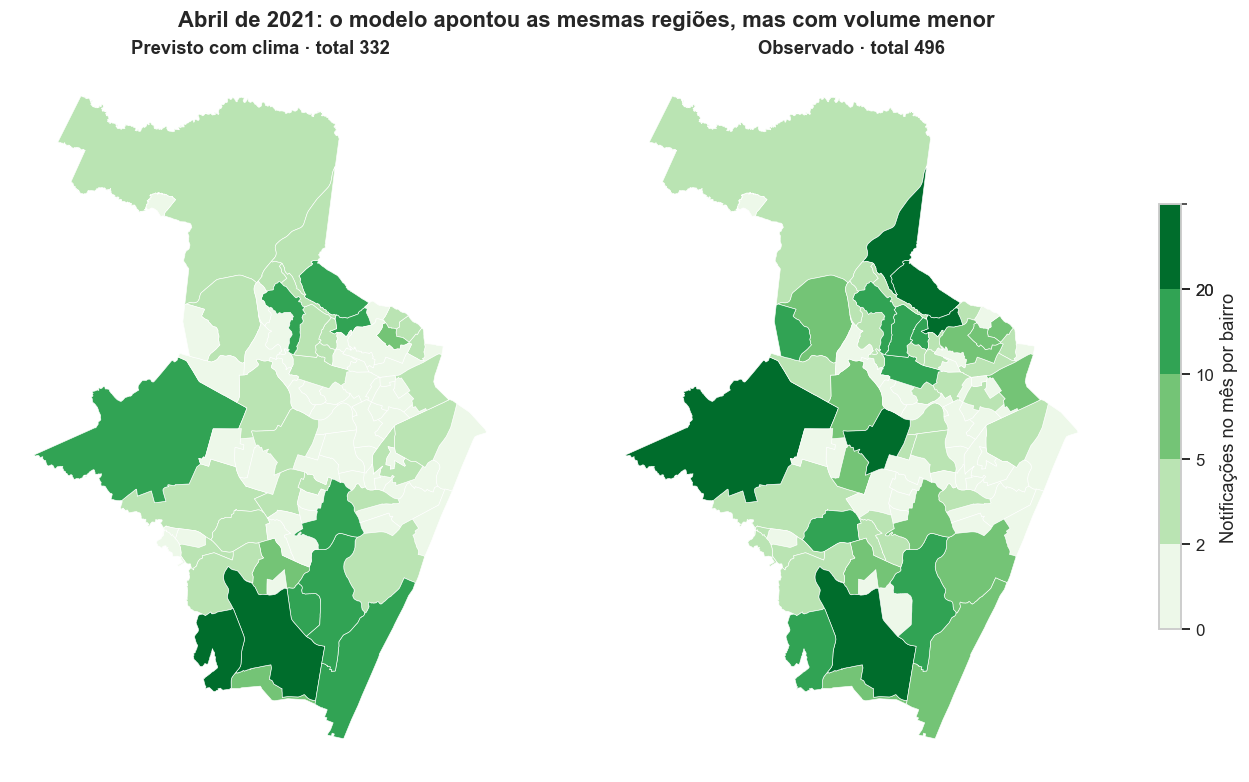

Bairros sem correspondência na malha: []


In [19]:
import json
import unicodedata
from matplotlib.collections import PatchCollection
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Polygon

def chave(nome):
    # Mesma normalização do painel: sem acentos, maiúsculas
    return ' '.join(''.join(ch for ch in unicodedata.normalize('NFKD', nome) if not unicodedata.combining(ch)).upper().split())

with open(raiz / 'prototype' / 'bairros-recife.geojson', encoding='utf-8') as arquivo:
    malha = json.load(arquivo)['features']

mes_mapa = pd.Timestamp('2021-04-01')
valores_mapa = pd.DataFrame({
    'previsto': previsoes_mes.loc[previsoes_mes['MES_ALVO'].eq(mes_mapa) & previsoes_mes['cenario'].eq('com clima')].set_index('BAIRRO')['previsto'],
    'observado': observados_mes.loc[observados_mes['MES_ALVO'].eq(mes_mapa)].set_index('BAIRRO')['observado'],
})
valores_mapa.index = valores_mapa.index.map(chave)

# Mesmas faixas de cor do painel web
faixas = [0, 2, 5, 10, 20, 1000]
paleta = ListedColormap(['#edf8e9', '#bae4b3', '#74c476', '#31a354', '#006d2c'])
norma = BoundaryNorm(faixas, paleta.N)

fig, eixos = plt.subplots(1, 2, figsize=(12, 7), layout='constrained')
for eixo, coluna, titulo in zip(eixos, ('previsto', 'observado'), ('Previsto com clima', 'Observado')):
    poligonos, cores_mapa = [], []
    for item in malha:
        valor = valores_mapa[coluna].get(chave(item['properties']['EBAIRRNOME']), np.nan)
        geometria = item['geometry']
        partes = geometria['coordinates'] if geometria['type'] == 'MultiPolygon' else [geometria['coordinates']]
        for parte in partes:
            poligonos.append(Polygon(parte[0], closed=True))
            cores_mapa.append(valor)
    colecao = PatchCollection(poligonos, cmap=paleta, norm=norma, edgecolor='white', linewidth=0.4)
    colecao.set_array(np.array(cores_mapa, dtype=float))
    eixo.add_collection(colecao)
    eixo.autoscale_view()
    eixo.set_aspect('equal')
    eixo.axis('off')
    eixo.set_title(f'{titulo} · total {valores_mapa[coluna].sum():,.0f}'.replace(',', '.'))

fig.colorbar(colecao, ax=eixos, shrink=0.6, label='Notificações no mês por bairro', ticks=faixas[:-1] + [20])

fig.suptitle('Abril de 2021: o modelo apontou as mesmas regiões, mas com volume menor', fontweight='bold')
plt.show()

print('Bairros sem correspondência na malha:', sorted(set(valores_mapa.index) - {chave(i['properties']['EBAIRRNOME']) for i in malha}))

> **❓ Pergunta:** O modelo aponta os bairros certos?
>
> **💡 Insight:** O padrão espacial previsto se parece com o observado: as regiões com mais notificações no mapa observado também aparecem mais escuras na previsão. O volume previsto é menor (332 contra 496 no total), coerente com a subestimação dos surtos. Para a vigilância, o mapa indica **onde priorizar**; o tamanho exato do aumento continua incerto.

### O mapa por outras lentes: erro, ganho do clima e bairros prioritários

O mesmo mapa responde a outras perguntas da gestão. À esquerda, **onde o modelo errou** em abril de 2021 (vermelho: previu menos que o observado; azul: previu mais). No centro, **onde o clima ajudou** no teste de quatro semanas: o verde indica bairros em que a versão com clima errou menos que a sem clima. À direita, **a lista de prioridade**: os dez bairros que o modelo apontaria em abril de 2021 comparados aos dez que de fato tiveram mais notificações.

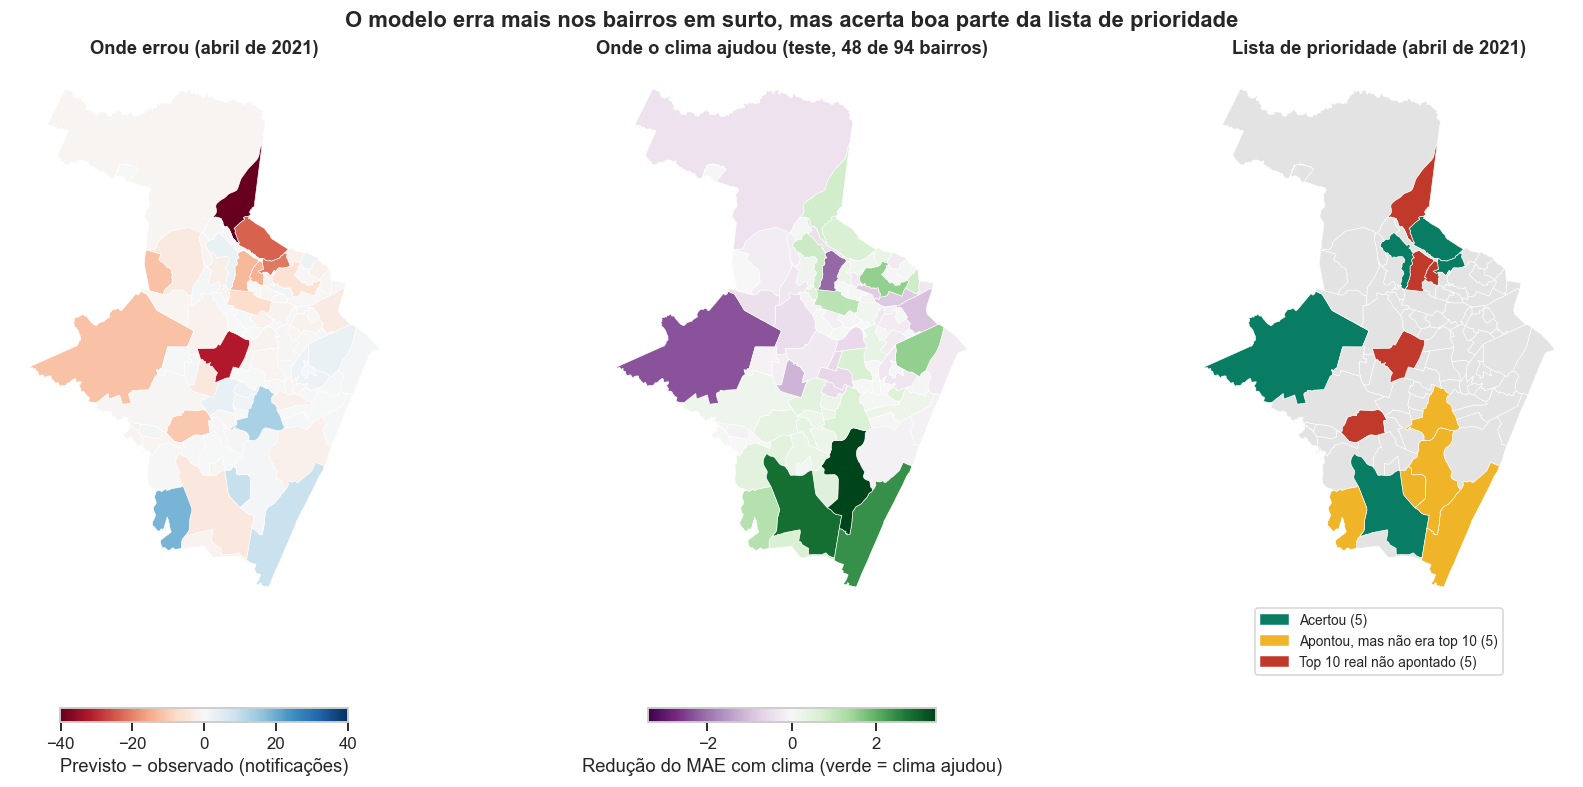

Bairros com maior subestimação em abril: {'PASSARINHO': -40.0, 'CORDEIRO': -32.0, 'DOIS UNIDOS': -24.0, 'LINHA DO TIRO': -21.0, 'ALTO JOSE BONIFACIO': -14.0}
Acertos do top 10: ['DOIS UNIDOS', 'IBURA', 'LINHA DO TIRO', 'NOVA DESCOBERTA', 'VARZEA']


In [20]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Patch

def pintar(eixo, valores, cmap, norm):
    # Desenha os bairros da malha coloridos pelo valor de cada um (cinza se não houver valor)
    poligonos, cores_bairro = [], []
    for item in malha:
        valor = valores.get(chave(item['properties']['EBAIRRNOME']), np.nan)
        geometria = item['geometry']
        partes = geometria['coordinates'] if geometria['type'] == 'MultiPolygon' else [geometria['coordinates']]
        for parte in partes:
            poligonos.append(Polygon(parte[0], closed=True))
            cores_bairro.append(valor)
    colecao = PatchCollection(poligonos, cmap=cmap, norm=norm, edgecolor='white', linewidth=0.4)
    colecao.set_array(np.ma.masked_invalid(np.array(cores_bairro, dtype=float)))
    cmap.set_bad('#e3e3e3')
    eixo.add_collection(colecao)
    eixo.autoscale_view()
    eixo.set_aspect('equal')
    eixo.axis('off')
    return colecao

# 1. Erro de abril de 2021 (previsto - observado)
erro_abril = valores_mapa['previsto'] - valores_mapa['observado']

# 2. Ganho do clima por bairro no teste de 4 semanas (MAE sem clima - MAE com clima)
teste4 = previsoes_teste.loc[previsoes_teste['horizonte_semanas'].eq(4)].assign(erro=lambda d: (d['previsto'] - d['observado']).abs())
mae_bairro = teste4.pivot_table(index='BAIRRO', columns='cenario', values='erro', aggfunc='mean')
ganho_bairro = (mae_bairro['sem clima'] - mae_bairro['com clima'])
ganho_bairro.index = ganho_bairro.index.map(chave)

# 3. Top 10 previsto x top 10 observado em abril de 2021
top_prev = set(valores_mapa['previsto'].nlargest(10).index)
top_obs = set(valores_mapa['observado'].nlargest(10).index)
categoria = pd.Series(np.nan, index=valores_mapa.index)
categoria[list(top_obs - top_prev)] = 0      # prioridade real que o modelo não apontou
categoria[list(top_prev - top_obs)] = 1      # apontado, mas não estava entre os 10 maiores
categoria[list(top_prev & top_obs)] = 2      # acerto

fig, eixos = plt.subplots(1, 3, figsize=(16, 7), layout='constrained')

limite = np.nanmax(np.abs(erro_abril))
c1 = pintar(eixos[0], erro_abril, plt.get_cmap('RdBu').copy(), TwoSlopeNorm(0, -limite, limite))

fig.colorbar(c1, ax=eixos[0], shrink=0.5, orientation='horizontal', label='Previsto − observado (notificações)')
eixos[0].set_title('Onde errou (abril de 2021)')

limite = np.nanmax(np.abs(ganho_bairro))
c2 = pintar(eixos[1], ganho_bairro, plt.get_cmap('PRGn').copy(), TwoSlopeNorm(0, -limite, limite))

fig.colorbar(c2, ax=eixos[1], shrink=0.5, orientation='horizontal', label='Redução do MAE com clima (verde = clima ajudou)')
eixos[1].set_title(f'Onde o clima ajudou (teste, {int((ganho_bairro > 0).sum())} de {len(ganho_bairro)} bairros)')

cores_top = ListedColormap(['#c0392b', '#f0b429', '#087d64'])
pintar(eixos[2], categoria, cores_top, BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3))
eixos[2].legend(handles=[Patch(color='#087d64', label=f'Acertou ({len(top_prev & top_obs)})'),
                         Patch(color='#f0b429', label=f'Apontou, mas não era top 10 ({len(top_prev - top_obs)})'),
                         Patch(color='#c0392b', label=f'Top 10 real não apontado ({len(top_obs - top_prev)})')],
                loc='upper center', bbox_to_anchor=(0.5, 0.02), fontsize=9)

eixos[2].set_title('Lista de prioridade (abril de 2021)')

fig.suptitle('O modelo erra mais nos bairros em surto, mas acerta boa parte da lista de prioridade', fontweight='bold')
plt.show()

print('Bairros com maior subestimação em abril:', erro_abril.nsmallest(5).round(0).to_dict())
print('Acertos do top 10:', sorted(top_prev & top_obs))

> **❓ Pergunta:** O que o mapa mostra além do total previsto?
>
> **💡 Insight:** Três coisas. **Onde errou:** os maiores erros de abril de 2021 são subestimações em bairros que entraram em surto no norte e no oeste (Passarinho, Cordeiro, Dois Unidos, Linha do Tiro), o mesmo padrão dos picos subestimados. **Onde o clima ajudou:** o ganho não é aleatório no território. Nos 20 bairros com mais notificações no teste, a versão com clima errou menos em **16**. Os maiores ganhos estão no sul (Imbiribeira, Ibura, Boa Viagem), e as maiores perdas, em Várzea e Vasco da Gama. Nos bairros com poucas notificações, as duas versões ficam praticamente empatadas, o que explica o placar geral apertado (48 de 94). Ou seja: **o clima ajuda justamente onde há mais dengue**, que é onde a Prefeitura mais precisa acertar. **Lista de prioridade:** dos dez bairros com mais notificações em abril, o modelo apontou cinco (incluindo Ibura, Várzea e Nova Descoberta). Os cinco que escaparam são surtos que cresceram rápido, e os cinco apontados por engano são bairros populosos da zona sul. Uma lista com metade de acerto já ajuda a direcionar as primeiras visitas, mas não substitui a vigilância local.

## Sensibilidades e utilidade territorial

Os testes de retirada de atributos foram feitos na validação. Como janelas, defasagens e medidas climáticas carregam informação em comum, a diferença de erro descreve a contribuição condicional de um grupo nesta amostra. A variante com população reconstruída é retrospectiva. A série complementar sem clima treina até 2021, valida em 2022–2023 e testa em 2024–2025. As duas análises preservam a avaliação climática original.

Como diagnóstico de uso, comparamos os dez bairros de maior volume previsto com os dez de maior volume observado nos sete meses pareados. A fração mede a parcela do total observado concentrada nos dez bairros indicados.

In [21]:
with ZipFile(raiz / 'AV2' / 'artefatos' / 'sensibilidades.zip') as registro:
    with registro.open('ablacoes_validacao.csv') as arquivo:
        ablac = pd.read_csv(arquivo)
    with registro.open('priorizacao_mensal.csv') as arquivo:
        prioridade = pd.read_csv(arquivo)

with ZipFile(raiz / 'AV2' / 'artefatos' / 'serie_sem_clima.zip') as registro:
    with registro.open('metricas.csv') as arquivo:
        serie_recente = pd.read_csv(arquivo)

display(ablac.pivot(index='variante', columns='semanas', values='MAE').round(3))
display(serie_recente.round(3))

prioridade.groupby('cenario').mean(numeric_only=True).round(3)

semanas,1,4
variante,,
com clima,0.851,3.081
com clima + população retrospectiva,0.898,3.374
sem chuva,0.853,3.123
sem clima,0.868,3.195
sem clima + população retrospectiva,0.917,3.405
sem janela 2 semanas,0.854,3.101
sem janela 4 semanas,0.846,3.068
sem janela 8 semanas,0.853,3.082
sem temperatura,0.841,3.014


,semanas,conjunto,modelo,inicio,fim,linhas,MAE,RMSE
0,1,validação,Persistência,2022-01-03,2023-12-25,9776,0.693,1.309
1,1,validação,Média das quatro semanas anteriores,2022-01-03,2023-12-25,9776,0.628,1.124
2,1,validação,Gradient Boosting,2022-01-03,2023-12-25,9776,0.647,1.060
3,1,teste,Persistência,2024-01-01,2025-12-22,9776,1.402,2.511
4,1,teste,Média das quatro semanas anteriores,2024-01-01,2025-12-22,9776,1.376,2.618
5,1,teste,Gradient Boosting,2024-01-01,2025-12-22,9776,1.261,2.482
6,4,validação,Persistência,2022-01-03,2023-12-25,9494,2.483,4.372
7,4,validação,Média das quatro semanas anteriores,2022-01-03,2023-12-25,9494,1.842,3.386
8,4,validação,Gradient Boosting,2022-01-03,2023-12-25,9494,1.807,3.141
9,4,teste,Persistência,2024-01-01,2025-12-22,9494,5.293,9.545


,bairros_em_comum_top10,fracao_notificacoes_nos_10_previstos
cenario,,
com clima,5.429,0.421
média móvel,4.714,0.401
sem clima,5.000,0.420


### Utilidade: o modelo acerta os bairros prioritários?

Para a Prefeitura, o que importa é saber quais bairros visitar primeiro. Em cada mês, comparamos os dez bairros com maior previsão com os dez que de fato tiveram mais notificações.

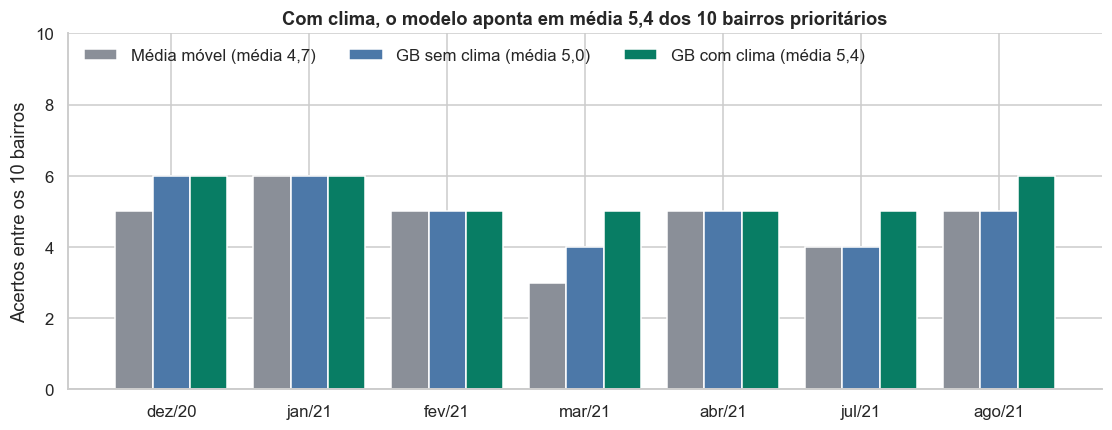

In [22]:
# Quantos dos 10 bairros com mais notificações no mês cada método apontou
prior_mes = prioridade.pivot(index='mes', columns='cenario', values='bairros_em_comum_top10')
prior_mes.index = [f'{meses_pt[d.month - 1]}/{d.year % 100:02d}' for d in pd.to_datetime(prior_mes.index)]

fig, ax = plt.subplots(figsize=(10, 3.8), layout='constrained')
largura = 0.27
for deslocamento, (tipo, rotulo, cor) in zip((-largura, 0, largura), [
        ('média móvel', 'Média móvel', cores['baseline']), ('sem clima', 'GB sem clima', cores['sem clima']), ('com clima', 'GB com clima', cores['com clima'])]):
    ax.bar(np.arange(len(prior_mes)) + deslocamento, prior_mes[tipo], width=largura, color=cor,
           label=f'{rotulo} (média ' + f'{prior_mes[tipo].mean():.1f}'.replace('.', ',') + ')')

ax.set_xticks(np.arange(len(prior_mes)), prior_mes.index)
ax.set(ylim=(0, 10), ylabel='Acertos entre os 10 bairros', title='Com clima, o modelo aponta em média 5,4 dos 10 bairros prioritários')
ax.legend(frameon=False, ncol=3, loc='upper left')
plt.show()

> **❓ Pergunta:** A previsão ajuda a escolher onde agir?
>
> **💡 Insight:** Sim, de forma modesta. Com clima, o modelo acerta em média 5,4 dos 10 bairros prioritários do mês, contra 5,0 sem clima e 4,7 da média móvel, e em nenhum mês ficou atrás das outras opções. Os dez bairros apontados concentram cerca de 42% das notificações do mês. É uma ajuda real para priorizar visitas, mas não substitui a avaliação das equipes em campo.

Variação do MAE ao acrescentar população retrospectiva: {'com clima + população retrospectiva': 0.293, 'sem clima + população retrospectiva': 0.324}


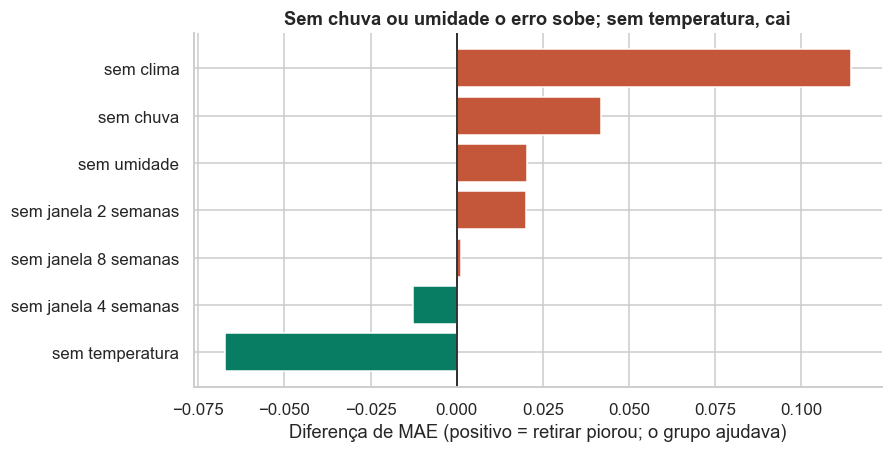

In [23]:
tabela_ablac = ablac.pivot(index='variante', columns='semanas', values='MAE')
referencia_ablac = tabela_ablac.loc['com clima', 4]

# População é outro assunto (sensibilidade retrospectiva): fica fora do gráfico e é impressa à parte
variacao = (tabela_ablac[4] - referencia_ablac).drop('com clima')
populacao = variacao[variacao.index.str.contains('população')]
variacao = variacao.drop(populacao.index).sort_values()
print('Variação do MAE ao acrescentar população retrospectiva:', populacao.round(3).to_dict())

fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
ax.barh(variacao.index, variacao, color=['#087d64' if v < 0 else '#c4563a' for v in variacao])
ax.axvline(0, color='black', linewidth=1)
ax.set(title='Sem chuva ou umidade o erro sobe; sem temperatura, cai',
       xlabel='Diferença de MAE (positivo = retirar piorou; o grupo ajudava)')

plt.show()

> **❓ Pergunta:** Quais grupos de variáveis fazem falta quando retirados?
>
> **💡 Insight:** Retirar chuva ou umidade aumentou o erro, então esses grupos ajudam. Retirar temperatura ou a janela de quatro semanas reduziu o erro nesta amostra. Adicionar população piorou o resultado, por isso ela ficou fora do modelo principal.

## Importância das variáveis

O `HistGradientBoostingRegressor` não oferece `feature_importances_`. Usamos **importância por permutação** (`sklearn.inspection.permutation_importance`): na validação, cada atributo é embaralhado dez vezes e medimos quanto o MAE aumenta. Quanto maior o aumento, mais o modelo depende daquele atributo. Valores próximos de zero ou negativos indicam que o atributo não ajudou nesta amostra. O modelo é o Gradient Boosting com clima ajustado só no treino; o teste reservado não é usado. O cálculo é feito por `python -B -m AV2.src.importancia_variaveis` e registrado em `AV2/artefatos/importancia_variaveis.zip`.

Atributos correlacionados dividem a importância entre si: embaralhar uma defasagem de chuva isolada pouco afeta o erro quando outras defasagens e janelas carregam informação parecida. Por isso a leitura por atributo complementa, mas não substitui, a retirada de grupos inteiros mostrada acima.

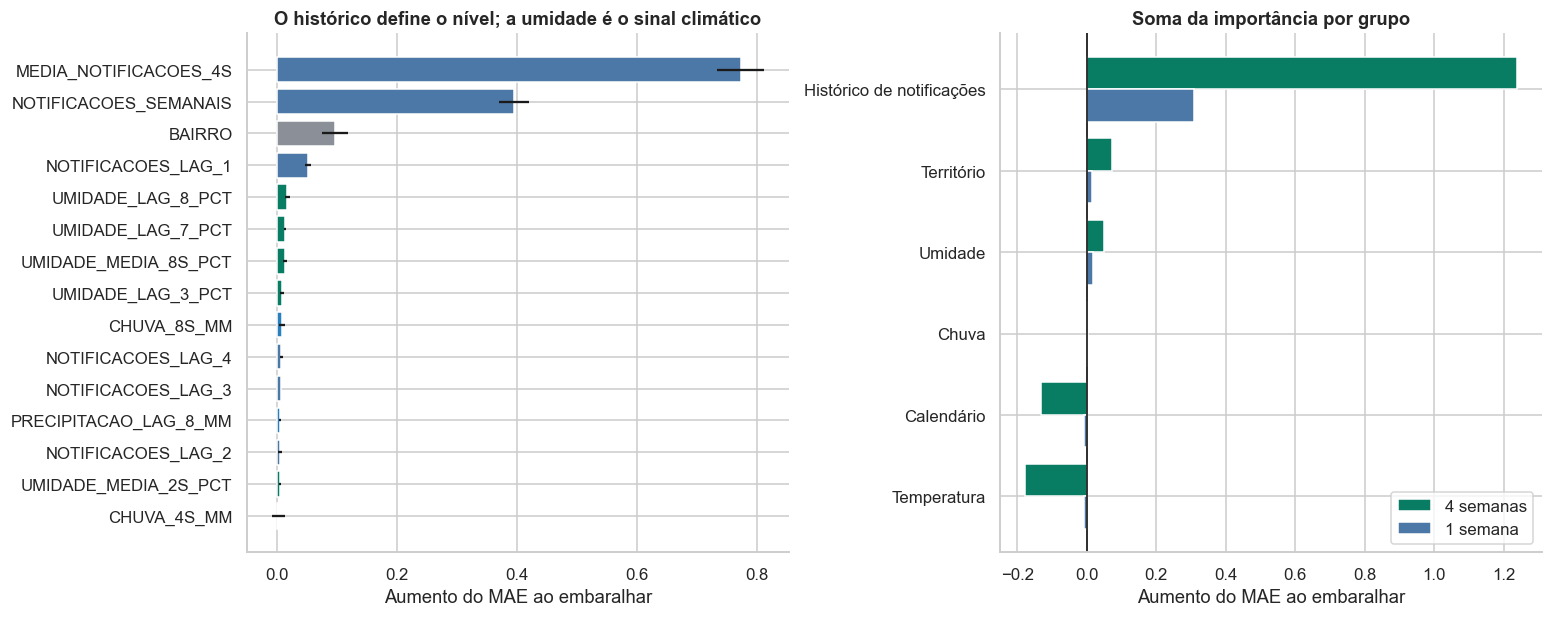

horizonte_semanas,1,4
grupo,,
Temperatura,-0.0080,-0.1784
Calendário,-0.0074,-0.1308
Chuva,0.0040,0.0001
Umidade,0.0167,0.0493
Território,0.0153,0.0717
Histórico de notificações,0.3074,1.2389


In [24]:
with ZipFile(raiz / 'AV2' / 'artefatos' / 'importancia_variaveis.zip') as registro:
    with registro.open('importancia.csv') as arquivo:
        importancia = pd.read_csv(arquivo)

# Importância por permutação: quanto o MAE piora ao embaralhar cada atributo
cores_grupo = {'Histórico de notificações': '#4c78a8', 'Território': '#8a8f98', 'Calendário': '#b07aa1',
               'Chuva': '#2a7fbf', 'Umidade': '#087d64', 'Temperatura': '#e08a2c'}

fig, eixos = plt.subplots(1, 2, figsize=(14, 5.5), layout='constrained')
topo = importancia.loc[importancia['horizonte_semanas'].eq(4)].nlargest(15, 'aumento_MAE').iloc[::-1]
eixos[0].barh(topo['atributo'], topo['aumento_MAE'], xerr=topo['desvio'], color=topo['grupo'].map(cores_grupo))
eixos[0].set(title='O histórico define o nível; a umidade é o sinal climático', xlabel='Aumento do MAE ao embaralhar')

por_grupo = importancia.groupby(['grupo', 'horizonte_semanas'])['aumento_MAE'].sum().unstack()
por_grupo = por_grupo.sort_values(4)
posicoes_g = range(len(por_grupo))
eixos[1].barh([p + 0.2 for p in posicoes_g], por_grupo[4], height=0.4, label='4 semanas', color='#087d64')
eixos[1].barh([p - 0.2 for p in posicoes_g], por_grupo[1], height=0.4, label='1 semana', color='#4c78a8')
eixos[1].set_yticks(list(posicoes_g), por_grupo.index)
eixos[1].axvline(0, color='black', linewidth=1)
eixos[1].set(title='Soma da importância por grupo', xlabel='Aumento do MAE ao embaralhar')
eixos[1].legend()
plt.show()

por_grupo.round(4)

> **❓ Pergunta:** Em quais variáveis o modelo se apoia?
>
> **💡 Insight:** O histórico recente de notificações define o **nível** da previsão: sozinho, explica a maior parte do acerto. O clima atua como ajuste fino. O sinal climático mais útil é a **umidade de sete a oito semanas antes**, prazo compatível com o acúmulo de criadouros e de gerações do mosquito antes do aumento dos registros, hipótese que a literatura entomológica pode confirmar. A temperatura tem importância negativa, coerente com a ablação.

### Por que a importância da chuva aparece pequena

O heatmap de correlação mostra, de uma vez, a força das relações entre variáveis numéricas. Aqui ele explica um efeito da importância por permutação: quando vários atributos carregam quase a mesma informação, embaralhar um deles pouco muda o erro, porque os outros compensam.

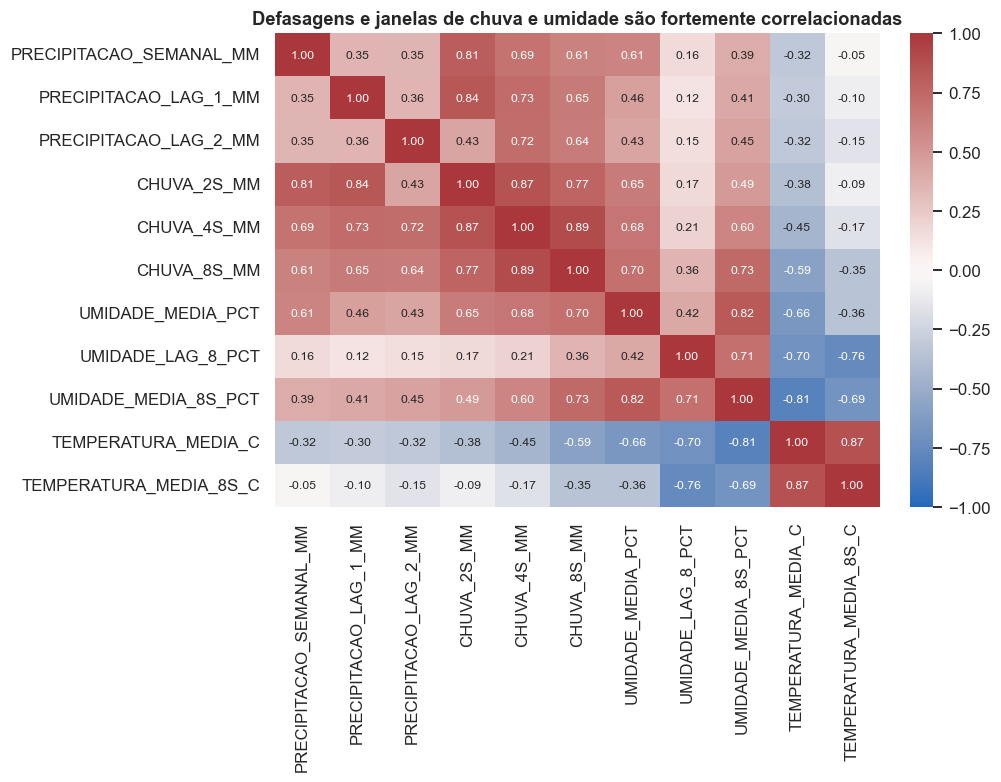

In [25]:
colunas_corr = ['PRECIPITACAO_SEMANAL_MM', 'PRECIPITACAO_LAG_1_MM', 'PRECIPITACAO_LAG_2_MM', 'CHUVA_2S_MM', 'CHUVA_4S_MM', 'CHUVA_8S_MM',
                'UMIDADE_MEDIA_PCT', 'UMIDADE_LAG_8_PCT', 'UMIDADE_MEDIA_8S_PCT', 'TEMPERATURA_MEDIA_C', 'TEMPERATURA_MEDIA_8S_C']

treino_clima = painel.loc[painel['CONJUNTO_4S'].eq('treino'), colunas_corr]

fig, ax = plt.subplots(figsize=(9, 7), layout='constrained')
sns.heatmap(treino_clima.corr(), annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, ax=ax, annot_kws={'size': 8})
ax.set_title('Defasagens e janelas de chuva e umidade são fortemente correlacionadas')
plt.show()

> **❓ Pergunta:** Os atributos climáticos repetem informação entre si?
>
> **💡 Insight:** Sim. As janelas de chuva se sobrepõem e se correlacionam fortemente com as semanas que as compõem, e chuva e umidade também andam juntas. Por isso a importância individual da chuva se dilui entre muitas colunas, enquanto retirar o grupo inteiro aumenta o erro. Para avaliar o clima, a leitura por grupo (ablação) é mais confiável que a de um atributo isolado. O heatmap também mostra a temperatura fortemente correlacionada, de forma negativa, com a umidade (cerca de −0,8): semanas mais quentes tendem a ser mais secas. Boa parte do que a temperatura informa já chega pela umidade, o que ajuda a explicar por que retirá-la não prejudicou o modelo.

### A temperatura no Recife

A ablação e a importância por permutação indicaram que a temperatura não ajuda o modelo nesta amostra. A temperatura importa para o mosquito *Aedes aegypti*, então vale entender por que ela não ajuda **aqui**. Comparamos a variação semanal das três medidas climáticas, uma linha por semana.

,TEMPERATURA_MEDIA_C,UMIDADE_MEDIA_PCT,PRECIPITACAO_SEMANAL_MM
mean,25.95,77.56,35.54
std,1.33,5.55,43.49
min,23.21,66.40,0.00
max,28.46,92.07,277.40


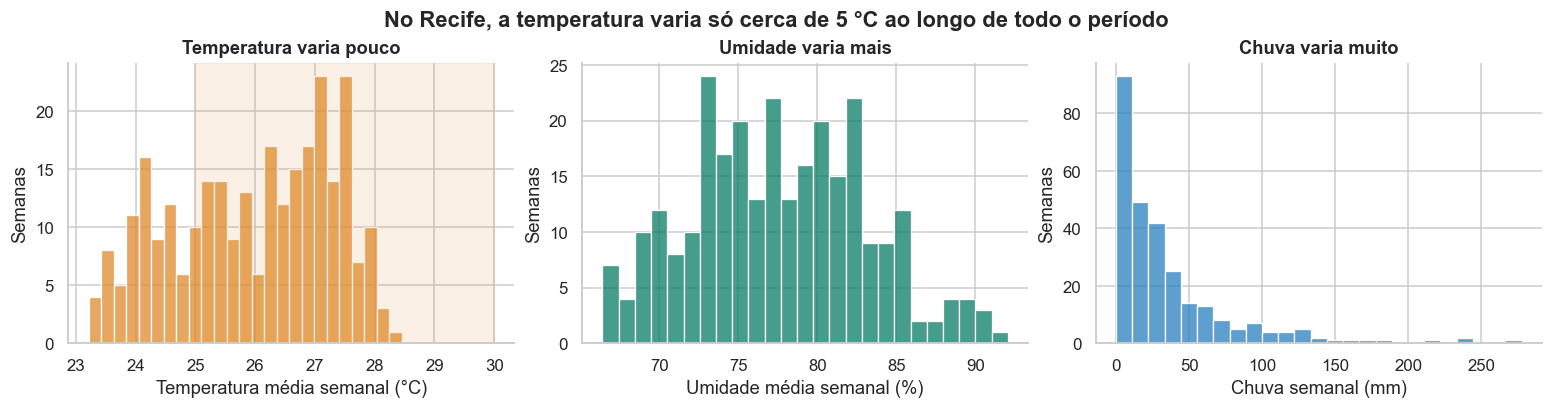

In [26]:
semanas_clima = (painel.drop_duplicates('DATA_SEMANA')
                 [['DATA_SEMANA', 'TEMPERATURA_MEDIA_C', 'UMIDADE_MEDIA_PCT', 'PRECIPITACAO_SEMANAL_MM']].dropna())

display(semanas_clima.drop(columns='DATA_SEMANA').describe().loc[['mean', 'std', 'min', 'max']].round(2))

fig, eixos = plt.subplots(1, 3, figsize=(14, 3.6), layout='constrained')
for eixo, (coluna, rotulo, cor) in zip(eixos, [
        ('TEMPERATURA_MEDIA_C', 'Temperatura média semanal (°C)', '#e08a2c'),
        ('UMIDADE_MEDIA_PCT', 'Umidade média semanal (%)', '#087d64'),
        ('PRECIPITACAO_SEMANAL_MM', 'Chuva semanal (mm)', '#2a7fbf')]):
    sns.histplot(semanas_clima[coluna], bins=25, color=cor, ax=eixo)
    eixo.set(xlabel=rotulo, ylabel='Semanas')

eixos[0].axvspan(25, 30, color='#e08a2c', alpha=0.12)
eixos[0].set_title('Temperatura varia pouco')
eixos[1].set_title('Umidade varia mais')
eixos[2].set_title('Chuva varia muito')

fig.suptitle('No Recife, a temperatura varia só cerca de 5 °C ao longo de todo o período', fontweight='bold')
plt.show()

> **❓ Pergunta:** Por que a temperatura ajuda tão pouco a prever?
>
> **💡 Insight:** Porque, no Recife, ela quase não muda: a média semanal fica entre cerca de 23 °C e 28 °C, com desvio de apenas 1,3 °C, e 72% das semanas ficam na faixa favorável ao mosquito (área sombreada, cerca de 25 a 30 °C); as demais ficam logo abaixo, entre 23 e 25 °C. Uma variável que quase não muda não ajuda a separar semanas de risco maior ou menor. Umidade e chuva variam muito mais. Além disso, o pouco que a temperatura informa já chega pela umidade (correlação de cerca de −0,8). Temperatura importa para a dengue, mas não serve para **distinguir** semanas num clima tão estável.

### Análise complementar posterior: clima sem temperatura

Diante desse resultado, avaliamos uma versão do Gradient Boosting com chuva e umidade, **sem temperatura**. A retirada foi decidida pela validação (MAE de quatro semanas de 3,081 para 3,014), com os mesmos cortes e parâmetros do teste oficial (`python -B -m AV2.src.avaliar_sem_temperatura`).

⚠️ **Atenção ao método:** o teste oficial já tinha sido registrado com o bloco climático completo. Por isso este resultado é uma **análise posterior** e **não substitui** o resultado oficial. Ele serve para verificar se a decisão tomada na validação se confirmaria em dados novos.

In [27]:
with ZipFile(raiz / 'AV2' / 'artefatos' / 'clima_sem_temperatura.zip') as registro:
    with registro.open('metricas.csv') as arquivo:
        metricas_sem_temp = pd.read_csv(arquivo)
    with registro.open('previsoes.csv') as arquivo:
        previsoes_sem_temp = pd.read_csv(arquivo)

comparacao = pd.concat([metricas_teste, metricas_sem_temp], ignore_index=True)
r2_todos = (pd.concat([previsoes_teste, previsoes_sem_temp]).groupby(['horizonte_semanas', 'cenario'])
            .apply(lambda g: r2_score(g['observado'], g['previsto']), include_groups=False).rename('R2'))

comparacao = comparacao.merge(r2_todos.reset_index(), on=['horizonte_semanas', 'cenario'])
ordem = {'baseline': 0, 'sem clima': 1, 'com clima': 2, 'clima sem temperatura': 3}
comparacao = comparacao.sort_values(['horizonte_semanas', 'cenario'], key=lambda s: s.map(ordem) if s.name == 'cenario' else s)
display(comparacao[['horizonte_semanas', 'cenario', 'MAE', 'RMSE', 'MAE_picos', 'MAE_municipal', 'R2']].round(3))

,horizonte_semanas,cenario,MAE,RMSE,MAE_picos,MAE_municipal,R2
0,1,baseline,1.132,3.188,7.143,32.364,0.349
1,1,sem clima,1.024,2.699,6.931,26.049,0.533
2,1,com clima,1.016,2.705,6.579,31.320,0.531
6,1,clima sem temperatura,1.029,2.761,6.678,29.841,0.512
3,4,baseline,3.835,10.833,18.166,210.567,0.360
4,4,sem clima,2.978,7.641,15.200,141.360,0.681
5,4,com clima,2.882,7.434,14.208,94.260,0.698
7,4,clima sem temperatura,2.936,7.807,14.403,110.615,0.667


> **❓ Pergunta:** A decisão de tirar a temperatura, tomada na validação, se confirma no teste?
>
> **💡 Insight:** Não. Na tabela, a versão sem temperatura errou **mais** que o modelo oficial com o clima completo: 2,936 contra 2,882 em quatro semanas e 1,029 contra 1,016 em uma semana. Em uma semana, ficou até um pouco pior que o modelo sem clima. Em quatro semanas, continua melhor que o modelo sem clima (2,978) e que a média móvel (3,835). A temperatura contribui pouco e de forma **instável**: atrapalhou no período de validação (2020) e ajudou um pouco no período de teste (2020–2021). É exatamente por isso que o protocolo não troca o modelo com base em uma única validação curta. **Decisão final: manter o bloco climático completo, como registrado.** A temperatura fica como variável de efeito pequeno e dependente do período, a reavaliar com mais anos de dados e mais estações.

## Ano de calendário (avaliação complementar, sem clima)

O painel também oferece uma visão anual por bairro. Ela é separada dos modelos acima: usa apenas os totais anuais de anos anteriores, sem clima, porque a cobertura climática não alcança 2022–2025. Três regras simples foram comparadas na validação de 2020 a 2023 (último ano, média e mediana dos três anos anteriores). A mediana dos três anos anteriores teve o menor MAE por bairro e foi aplicada ao teste de 2024 e 2025 e à estimativa de 2026, com base consolidada até dezembro de 2025. O cálculo é feito por `python -B -m AV2.src.avaliar_ano_calendario`.

,conjunto,ano,regra,MAE_bairro,erro_recife
0,validação,2020–2023,Último ano,55.70,NaN
1,validação,2020–2023,Média dos três anos anteriores,41.15,NaN
2,validação,2020–2023,Mediana dos três anos anteriores,40.67,NaN
3,teste,2024,Mediana dos três anos anteriores,73.07,-6865.0
4,teste,2025,Mediana dos três anos anteriores,58.14,-5449.0


,observado,previsto
ano,,
2023,3522.0,NaN
2024,10548.0,3683.0
2025,9150.0,3701.0
2026,NaN,8228.0


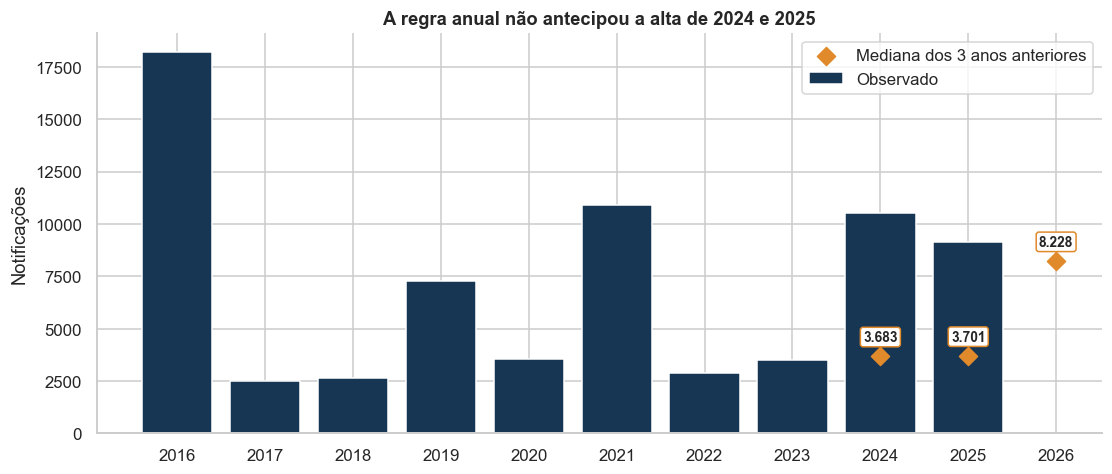

In [28]:
with ZipFile(raiz / 'AV2' / 'artefatos' / 'previsao_anual.zip') as registro:
    with registro.open('previsoes.csv') as arquivo:
        anual = pd.read_csv(arquivo)
    with registro.open('metricas.csv') as arquivo:
        metricas_anual = pd.read_csv(arquivo)

display(metricas_anual.round(2))

recife_ano = anual.groupby('ano')[['observado', 'previsto']].sum(min_count=1)
display(recife_ano.loc[2023:].round(0))

fig, ax = plt.subplots(figsize=(10, 4.2), layout='constrained')
observados_ano = recife_ano['observado'].dropna()
ax.bar(observados_ano.index, observados_ano, color='#173653', label='Observado')
previstos_ano = recife_ano['previsto'].dropna()
ax.scatter(previstos_ano.index, previstos_ano, color='#e08a2c', marker='D', s=70, zorder=3, label='Mediana dos 3 anos anteriores')
for ano_, valor in previstos_ano.items():
    ax.annotate(f'{valor:,.0f}'.replace(',', '.'), (ano_, valor), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=9, fontweight='bold',
                bbox={'boxstyle': 'round,pad=0.2', 'facecolor': 'white', 'edgecolor': '#e08a2c'})

ax.set(title='A regra anual não antecipou a alta de 2024 e 2025', ylabel='Notificações', xticks=list(range(2016, 2027)))
ax.legend()
plt.show()

> **❓ Pergunta:** Dá para prever o ano inteiro?
>
> **💡 Insight:** A regra anual mais simples subestimou fortemente 2024 e 2025, anos de alta depois de anos baixos: a mediana dos três anos anteriores não antecipa mudanças de patamar. A estimativa de 8.228 para 2026 deve ser lida como ordem de grandeza, com alta incerteza.

## Conclusões

**Modelo final escolhido:** Gradient Boosting com clima, horizonte de quatro semanas.

### O fio da história

Os resultados parecem misturados (o clima ajuda em quatro semanas, quase nada em uma semana, ajuda o total da cidade e não o mês por bairro), mas contam uma história coerente: **o histórico diz o nível; o clima ajuda a antecipar a virada.** Por isso o ganho aparece no médio prazo e no agregado municipal, onde a tendência importa mais que o ruído de cada bairro. A análise de defasagens confirma: chuva e umidade têm correlação de cerca de 0,45 com as notificações de 4 a 6 semanas depois, e o pico da chuva (março e abril) antecede o pico das notificações (maio e junho).

**Recomendação para a gestão.** Os dados apoiam três usos práticos: (1) tratar a subida da chuva e da umidade, em março e abril, como **alerta antecipado** para reforçar a eliminação de criadouros cerca de um mês antes do pico; (2) usar a previsão de quatro semanas por bairro para **ordenar as visitas**, começando pelos bairros apontados, que acertaram metade da lista de prioridade e onde o clima mais ajudou (16 dos 20 com mais dengue); (3) usar a previsão semanal para ajustes de curto prazo. O modelo **apoia** a decisão; não substitui a vigilância nem a investigação local de surtos.

**Na prática.** No recorte mensal, os dez bairros apontados pela versão com clima incluíram em média 5,4 dos dez com mais notificações, contra 4,7 da média móvel. É uma ajuda modesta, mas real, para priorizar visitas e inspeções.

**Resposta à pergunta da AV2.** No teste, o Gradient Boosting com clima obteve MAE de 2,88 notificações por bairro para quatro semanas, ante 2,98 sem clima e 3,84 para a média móvel. O ganho de MAE ao acrescentar variáveis climáticas foi de 3,2%. A diferença frente à média móvel foi de 24,9% e combina as mudanças de algoritmo e de atributos. Na próxima semana, o ganho incremental de clima foi menor, de 0,8%, e o agregado municipal apresentou menor erro no Gradient Boosting sem clima. O clima acrescenta informação, mas pouca, e de forma mais clara no horizonte de quatro semanas. O *bootstrap* em blocos mostra que o ganho do ML sobre a média móvel é sólido (positivo em 99% dos sorteios), enquanto o ganho do clima é provável, mas não comprovado: positivo em cerca de 87% dos sorteios, com intervalo de 95% entre cerca de −3% e +8%. Por isso tratamos o efeito do clima como **indício**, não como prova.

**Onde o modelo erra.** O ganho de quatro semanas foi desigual: o clima reduziu o MAE em 48 dos 94 bairros, mas em 16 dos 20 com mais notificações; nos bairros com poucos registros, as duas versões praticamente empatam. Os maiores erros são picos subestimados, como no Ibura, onde a janela iniciada em 21/06/2021 teve 141 notificações e previsão aproximada de 49. O resultado é retrospectivo, com dados de uma estação climática e registros consolidados.

**O que o modelo usa.** A importância por permutação mostra que o histórico recente de notificações (média de quatro semanas e contagem da semana) domina as previsões, seguido do bairro. Entre as variáveis climáticas, a umidade, sobretudo defasada em sete e oito semanas, foi a mais útil. A temperatura teve importância negativa, em linha com a retirada do grupo, que reduziu o erro na validação. A chuva tem importância individual pequena porque se distribui entre muitas defasagens correlacionadas; retirar o grupo inteiro aumentou o MAE.

**Mês de calendário.** Nos sete meses avaliados, o Gradient Boosting superou a média móvel no MAE por bairro. O clima elevou ligeiramente esse MAE (de 3,93 para 4,00), mas reduziu o erro absoluto médio do total municipal (de 220,16 para 207,19). Em abril de 2021 o Recife subiu de 258 para 496 notificações nos bairros do painel, e a versão integrada captou a alta com previsão de 332. De julho para agosto, porém, o observado caiu e o modelo indicou nova alta. A janela móvel de quatro semanas e o mês civil são avaliações distintas e não devem ser misturadas.

**Ano de calendário.** A regra anual sem clima previu 3.683 notificações em 2024 (observadas 10.548) e 3.701 em 2025 (observadas 9.150). A estimativa para 2026 é de 8.228. Os erros dos dois anos de teste mostram que a previsão anual tem alta incerteza e serve como ordem de grandeza, não como meta.

**Generalização.** No teste sem clima de 2024–2025, o Gradient Boosting teve MAE de 4,021 para quatro semanas, ante 4,704 da média móvel. Adicionar população e densidade retrospectivas piorou a validação. No recorte mensal, o cenário integrado identificou em média 5,4 dos dez bairros de maior volume observado.

**Temperatura.** No Recife, a temperatura semanal fica entre cerca de 23 °C e 28 °C (72% das semanas na faixa favorável ao mosquito, de 25 a 30 °C) e repete a informação da umidade. Por isso ajuda pouco a distinguir semanas. Testamos, como análise posterior, o modelo sem ela: no teste, ele errou mais que o oficial (2,936 contra 2,882 em quatro semanas). Mantivemos o bloco climático completo.

**Robustez.** O ganho do clima se manteve em 10 de 12 configurações de hiperparâmetros na validação, e o modelo explica cerca de 70% da variação (R²) em quatro semanas. A conclusão não depende de uma escolha específica de parâmetros.

**Pontos fortes.** (1) Comparação justa: o mesmo modelo foi treinado com e sem clima, nas mesmas linhas, datas e métricas, e ambos foram comparados com um método simples (média móvel). (2) Separação no tempo: treino, validação e teste em ordem cronológica, com o teste usado uma única vez, depois de todas as escolhas. (3) Ganho claro sobre o método simples: 24,9% menos erro e R² de 0,70 em quatro semanas, com ganho em 99,5% dos sorteios do *bootstrap*. (4) Resultado estável: o ganho do clima se manteve em 10 de 12 configurações de hiperparâmetros, e o modelo sem clima também superou a média móvel em 2024–2025 (MAE de 4,021 contra 4,704). (5) Resultado útil para a gestão: previsão por bairro, lista de prioridade (5,4 de 10 bairros por mês) e um painel com mapa de risco. (6) Reprodutível: todo o processamento está em `AV2/src/`, e as execuções guardam métricas, previsões e manifesto em `AV2/artefatos/`.

**Qualidade dos dados e problemas encontrados.** As notificações A90 são registros de suspeita, não casos confirmados, e chegam com atraso e revisões; por isso o alvo é tratado como contagem de notificações. O clima vem de uma única estação do INMET para a cidade inteira e só cobre 2016–2021; dentro do teste há lacunas (sem clima de 12/04 a 21/06/2021 e depois de 26/07/2021), que reduziram as janelas comparáveis entre os cenários. As contagens por bairro são pequenas (em 57% das semanas o bairro não tem nenhuma notificação), o que levou ao uso da perda de Poisson, própria para contagens. O volume varia muito entre anos (mais de 18 mil notificações em 2016 e cerca de 2,5 mil em 2017), o que dificulta prever o tamanho dos surtos. A pandemia de COVID-19 mudou a procura por atendimento justamente no período de validação e teste. Na revisão da AV1, a base foi auditada e a população anual por bairro foi corrigida antes da modelagem.

**Limitações.** Notificações não são casos confirmados; há atrasos e revisões de registro; uma única estação representa o clima de toda a cidade; a cobertura climática limita a comparação a 2016–2021; a validação é curta; o corte de treino (16/03/2020) coincide com o início da pandemia de COVID-19 no Brasil, e a validação e o teste (até novembro de 2021) caem nesse período, quando a procura por atendimento e a notificação de dengue mudaram; um único ano de teste não basta para comprovar estatisticamente o ganho do clima; a temperatura teve efeito pequeno e instável (piorou a validação, mas sua retirada piorou o teste, em análise posterior), porque varia pouco no clima do Recife; os picos são subestimados.

**Melhorias futuras.** Usar uma configuração mais simples do Gradient Boosting (taxa de aprendizado 0,05), que errou menos na validação, e buscar regularização de forma sistemática; mais estações ou sensores por bairro; dados disponíveis exatamente na data de emissão (com atraso de publicação); revisão do bloco de temperatura em novo protocolo; modelos específicos para picos; avaliação mensal com mais meses.

As melhorias com mais potencial, em ordem:

1. **Mais anos de clima.** Completar 2022 a 2025 com outra estação do INMET ou com reanálise por satélite (por exemplo, ERA5). Isso daria mais exemplos ao modelo e um novo teste **fora da pandemia**, a única forma de comprovar (ou descartar) o ganho do clima.
2. **Dados do mosquito.** O índice de infestação larvária por bairro (LIRAa) mede o criadouro, o elo entre a chuva e a dengue. É o candidato mais forte para prever o **tamanho** dos surtos.
3. **Previsão em faixa.** Informar um intervalo (por exemplo, "entre 300 e 600 notificações") em vez de um número só, com regressão por quantis. Não acerta mais, mas mostra a incerteza e ajuda a planejar o pior caso.
4. **Modelo para picos.** Tratar separadamente os surtos, que hoje são subestimados.

### Até onde confiar na previsão: quando, onde e quanto

A pergunta "o modelo prevê corretamente?" tem três respostas diferentes, conforme o que se quer saber. É como a previsão do tempo: o meteorologista acerta que vai chover e mais ou menos onde, mas não sabe quantos milímetros vão cair na sua rua.

| Pergunta | Nível | Evidência neste notebook | Como usar |
|---|---|---|---|
| **Quando** o risco sobe? | 🟢 **Bom** | Chuva e umidade têm correlação de cerca de 0,45 com as notificações de 4 a 6 semanas depois; a chuva sobe em março e abril e as notificações chegam ao pico em maio e junho. No teste, a versão com clima ficou mais perto do total da cidade que a média móvel em 29 de 30 janelas, e o R² de quatro semanas foi 0,70. Em abril de 2021, antecipou a alta (de 258 para 496 notificações; previsão de 332). | Tratar a chuva de março e abril como **alerta antecipado** e reforçar a prevenção cerca de um mês antes do pico. |
| **Onde** agir primeiro? | 🟡 **Razoável** | Na média dos meses avaliados, os dez bairros apontados incluíram 5,4 dos dez com mais notificações (4,7 na média móvel). Em abril de 2021, 5 de 10. O clima ajudou em 16 dos 20 bairros com mais notificações. | **Ordenar as visitas**, começando pelos bairros apontados, sem deixar de olhar a vigilância local: metade da lista real escapa. |
| **Quanto** vai aumentar? | 🔴 **Fraco nos surtos** | O erro médio é baixo (2,9 notificações por bairro em quatro semanas), mas nos surtos o modelo fica abaixo: em 73% das janelas com mais de 30 notificações previu menos que o observado. No Ibura, previu cerca de 49 onde vieram 141. De julho para agosto de 2021, previu alta e as notificações caíram. | Usar o número previsto como **piso**, não como teto, ao dimensionar equipes e insumos. |

**E o clima?** O ganho do clima na previsão é **provável, mas não comprovado** (positivo em 87% dos sorteios do *bootstrap*). O valor mais claro do clima está no **quando**: ele muda antes de a alta aparecer nos registros. A chuva, porém, não diz o **tamanho** do ano: choveu tanto em 2016 (mais de 18 mil notificações) quanto em 2017 (cerca de 2,5 mil).

**Por que não melhoramos o modelo agora?** O teste reservado já foi usado uma vez, como manda o protocolo. Ajustar o modelo e testar de novo no mesmo período seria como refazer a prova já sabendo as respostas: o número melhoraria, mas deixaria de valer. As melhorias ficam registradas abaixo, para um novo ciclo com dados novos.